<a href="https://colab.research.google.com/github/neouuuu/TPE-Fundamentos-de-la-Ciencia-de-Datos/blob/main/TPE_Ciencia_de_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Especial — Fundamentos de la Ciencia de Datos (Cursada 2026)

**Grupo 33:** Neo Allende · Francisco Maiaru · Manuel Lara Lambrecht

**Dataset asignado:** CKD-NHANES (encuesta NHANES, ciclo 2021-2023).

Esta notebook contiene el código del análisis. La descripción de la fuente de datos y la discusión de los resultados están en el informe, que referencia las secciones numeradas de esta notebook.

| Sección | Contenido |
| :--- | :--- |
| **0** | Configuración inicial |
| **1** | Análisis exploratorio inicial |
| **2** | Limpieza de la base |
| **3** | Hipótesis: planteo y validación (tres propias y tres de la cátedra) |

# 0. Configuración inicial

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import sweetviz as sv
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", None)   # la base tiene 29 variables
sns.set_theme(style="whitegrid")

ALFA = 0.05      # nivel de significancia de todos los tests
SEMILLA = 42     # semilla para resultados reproducibles

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Análisis exploratorio inicial

## 1.1 Carga de los datos
El archivo `dataset.csv` está en el repositorio, en la misma carpeta que esta notebook.

In [ ]:
dataframe = pd.read_csv("dataset.csv")
print(f"Filas: {dataframe.shape[0]} | Columnas: {dataframe.shape[1]}")
dataframe.head(15)

Filas: 11933 | Columnas: 29


,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
5,130383.0,3.0,Female,Other Hispanic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
6,130384.0,43.0,Male,Mexican American,2.0,0.63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,2.0,NaN,NaN,Unknown,1
7,130385.0,65.0,Female,Non-Hispanic White,3.0,5.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,2.0,2.0,NaN,NaN,Unknown,1
8,130386.0,34.0,Male,Mexican American,4.0,1.33,30.2,90.6,173.3,110.0,72.0,0.82,17.0,4.3,3.3,21.0,9.5,6.0,113.0,4.60,4.07,2.0,NaN,NaN,1.0,3.0,118.21,No CKD,0
9,130387.0,68.0,Female,Non-Hispanic White,5.0,1.32,42.6,103.5,155.9,143.0,76.0,0.76,15.0,3.7,3.5,24.0,9.3,6.2,23.0,5.93,25.78,2.0,NaN,NaN,2.0,NaN,85.30,Stage 2 (Mildly Decreased),1


## 1.2 Estructura general
Tipos de datos, valores no nulos por variable y filas duplicadas.

In [ ]:
dataframe.info()
print("Filas duplicadas:", dataframe.duplicated().sum())
print("participant_id repetidos:", dataframe["participant_id"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

## 1.3 Valores nulos
Se cuantifican los nulos y se analiza cómo dependen de la edad, porque muchas preguntas y mediciones de NHANES solo se aplican a ciertos rangos de edad.

In [ ]:
resumen_nulos = (
    pd.DataFrame({
        "cantidad": dataframe.isna().sum(),
        "porcentaje": (dataframe.isna().mean() * 100).round(2),
    })
    .query("cantidad > 0")
    .sort_values("porcentaje", ascending=False)
)
resumen_nulos

,cantidad,porcentaje
insulin_use,10852,90.94
diabetes_pills,9652,80.88
current_smoker,8690,72.82
phosphorus,5611,47.02
bicarbonate,5608,47.00
egfr,5607,46.99
blood_urea_nitrogen,5607,46.99
serum_creatinine,5607,46.99
uric_acid,5604,46.96
calcium,5571,46.69


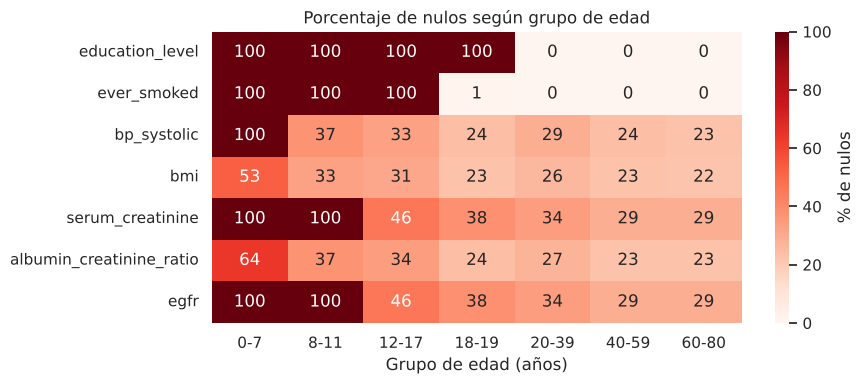

In [ ]:
# Porcentaje de nulos de variables clave según el grupo de edad
grupos_edad = pd.cut(
    dataframe["age"], bins=[-1, 7, 11, 17, 19, 39, 59, 80],
    labels=["0-7", "8-11", "12-17", "18-19", "20-39", "40-59", "60-80"],
)
variables_clave = ["education_level", "ever_smoked", "bp_systolic", "bmi",
                   "serum_creatinine", "albumin_creatinine_ratio", "egfr"]
nulos_por_edad = dataframe[variables_clave].isna().groupby(grupos_edad, observed=True).mean().mul(100).round(0)

plt.figure(figsize=(9, 4))
sns.heatmap(nulos_por_edad.T, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% de nulos"})
plt.xlabel("Grupo de edad (años)")
plt.title("Porcentaje de nulos según grupo de edad")
plt.tight_layout()
plt.show()

## 1.4 Variables numéricas: distribución y outliers
Descriptivos, asimetría, outliers según el criterio del rango intercuartil (IQR) e histogramas.

In [ ]:
# Categóricas codificadas con números (se analizan en 1.5)
VARS_CODIFICADAS = ["education_level", "diabetes_diagnosed", "insulin_use",
                    "diabetes_pills", "ever_smoked", "current_smoker"]
# Variables numéricas propiamente dichas
VARS_NUMERICAS = [c for c in dataframe.select_dtypes("number").columns
                  if c not in VARS_CODIFICADAS + ["participant_id", "ckd_present"]]

descriptivos = dataframe[VARS_NUMERICAS].describe().T
descriptivos["asimetria"] = dataframe[VARS_NUMERICAS].skew()
descriptivos.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetria
age,11933.0,38.32,25.60,0.00,13.00,37.00,62.00,80.00,0.09
poverty_income_ratio,9892.0,2.71,1.67,0.00,1.18,2.50,4.50,5.00,0.12
bmi,8471.0,27.25,8.14,11.10,21.60,26.40,31.70,74.80,0.91
weight_kg,8754.0,70.55,30.39,2.70,54.20,71.70,89.10,248.20,0.11
height_cm,8499.0,159.66,19.86,79.10,154.40,163.60,172.10,200.70,-1.51
bp_systolic,7517.0,119.29,18.56,61.00,106.00,117.00,130.00,232.00,0.97
bp_diastolic,7517.0,72.75,11.90,33.00,64.00,72.00,80.00,142.00,0.51
serum_creatinine,6326.0,0.87,0.39,0.33,0.70,0.83,0.98,15.17,15.61
blood_urea_nitrogen,6326.0,14.66,5.75,4.00,11.00,14.00,17.00,74.00,2.34
albumin_serum,6366.0,4.10,0.36,2.20,3.90,4.10,4.30,5.50,-0.42


In [ ]:
def resumen_outliers(df, columnas):
    """Cuenta outliers con el criterio de Tukey: fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]."""
    filas = []
    for col in columnas:
        x = df[col].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        cantidad = ((x < inferior) | (x > superior)).sum()
        filas.append({"variable": col, "minimo": x.min(), "maximo": x.max(),
                      "limite_inferior": inferior, "limite_superior": superior,
                      "outliers": cantidad, "% outliers": 100 * cantidad / len(x)})
    return pd.DataFrame(filas).set_index("variable").round(2)

resumen_outliers(dataframe, VARS_NUMERICAS)

,minimo,maximo,limite_inferior,limite_superior,outliers,% outliers
variable,,,,,,
age,0.00,80.00,-60.50,135.50,0,0.00
poverty_income_ratio,0.00,5.00,-3.80,9.48,0,0.00
bmi,11.10,74.80,6.45,46.85,189,2.23
weight_kg,2.70,248.20,1.85,141.45,137,1.56
height_cm,79.10,200.70,127.85,198.65,770,9.06
bp_systolic,61.00,232.00,70.00,166.00,143,1.90
bp_diastolic,33.00,142.00,40.00,104.00,93,1.24
serum_creatinine,0.33,15.17,0.28,1.40,183,2.89
blood_urea_nitrogen,4.00,74.00,2.00,26.00,194,3.07


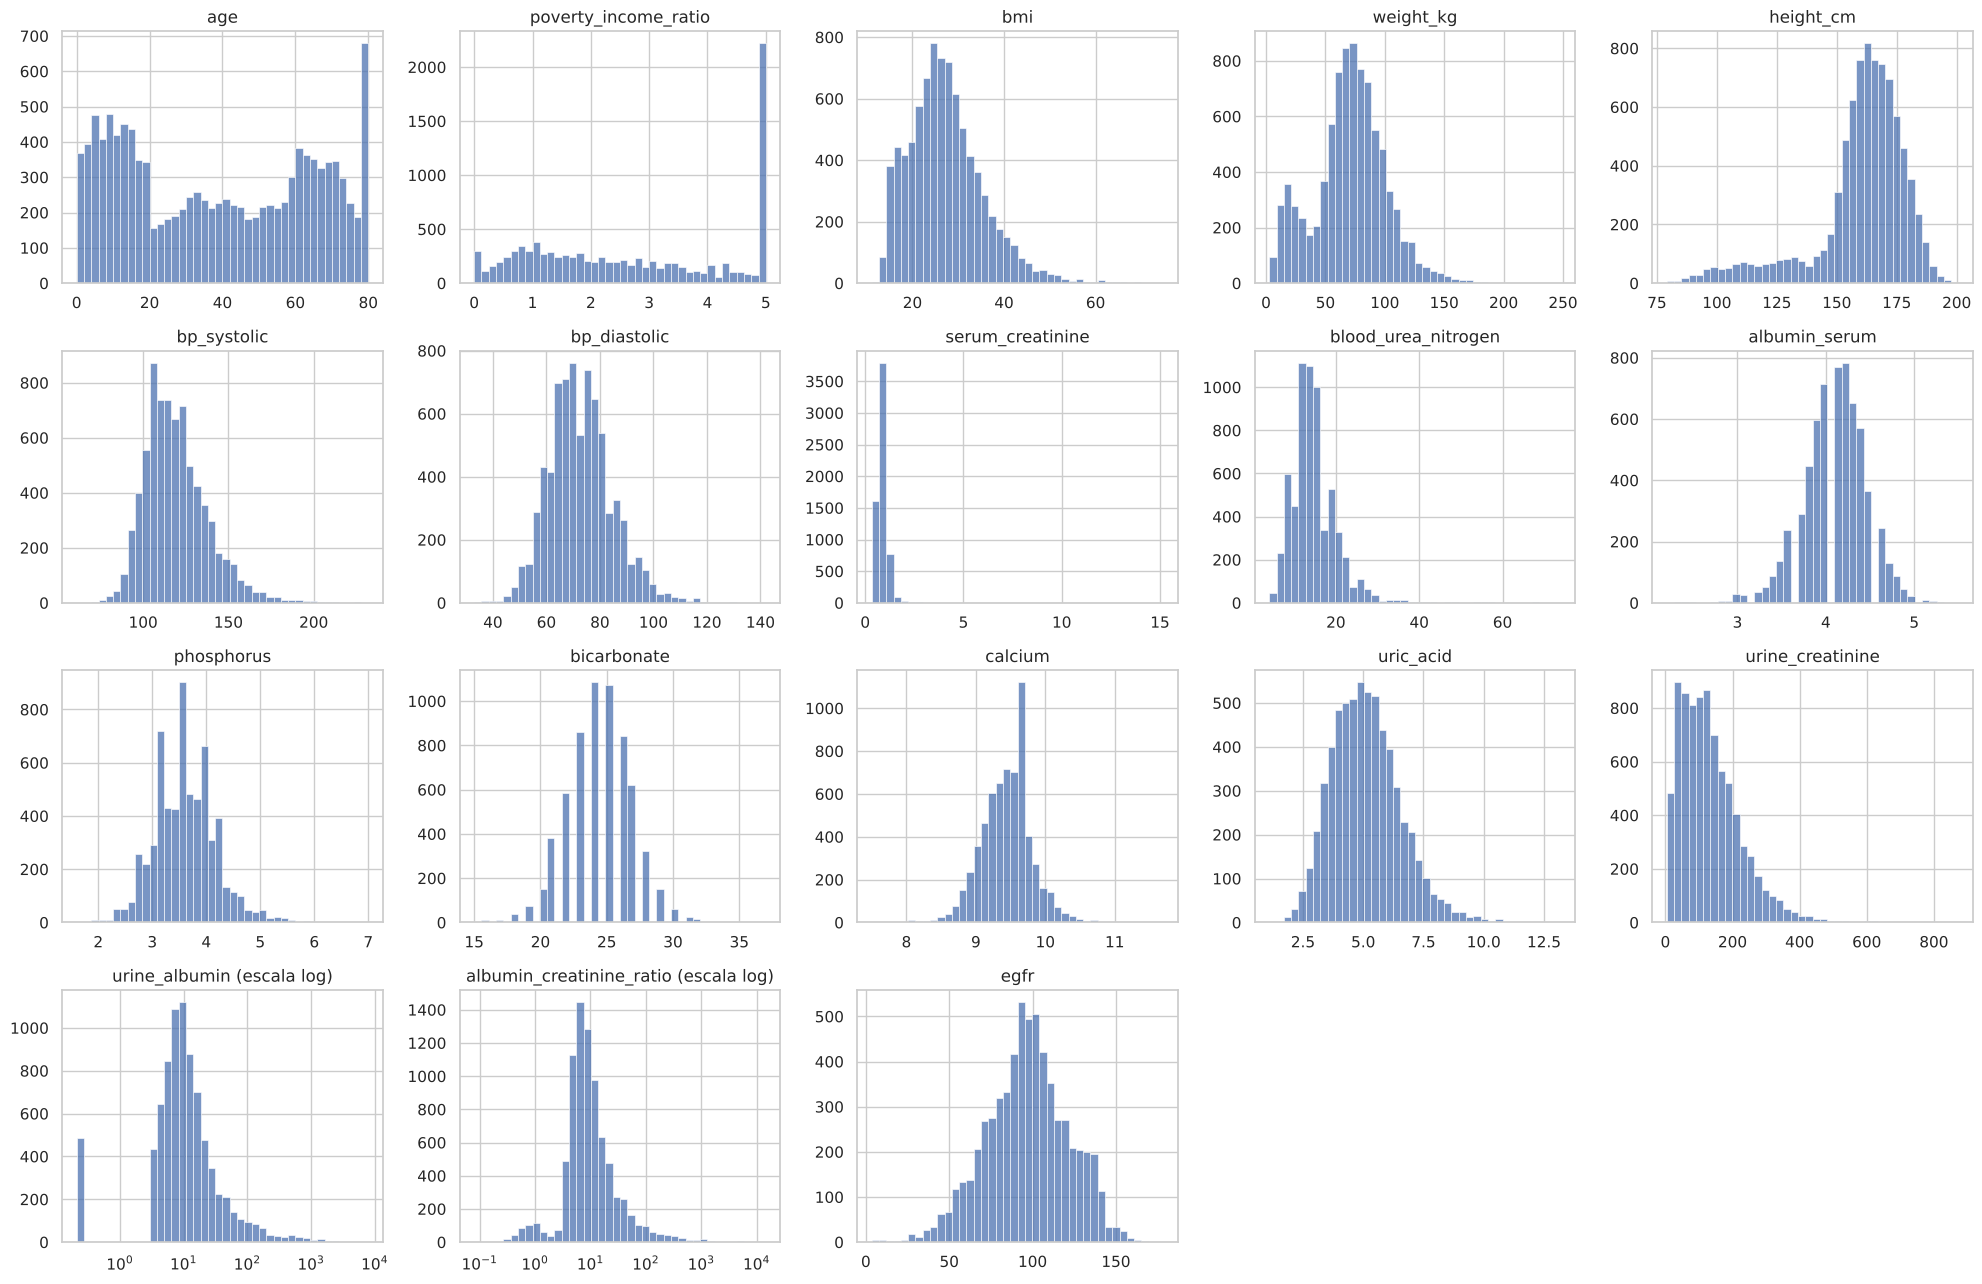

In [ ]:
# Histogramas; las dos variables urinarias con colas muy largas van en escala logarítmica
VARS_ESCALA_LOG = ["urine_albumin", "albumin_creatinine_ratio"]

fig, ejes = plt.subplots(4, 5, figsize=(20, 13))
for eje, col in zip(ejes.ravel(), VARS_NUMERICAS):
    sns.histplot(dataframe[col].dropna(), bins=40, log_scale=col in VARS_ESCALA_LOG, ax=eje)
    eje.set_title(col + (" (escala log)" if col in VARS_ESCALA_LOG else ""))
    eje.set(xlabel="", ylabel="")
for eje in ejes.ravel()[len(VARS_NUMERICAS):]:
    eje.set_visible(False)
plt.tight_layout()
plt.show()

## 1.5 Variables categóricas
Frecuencia de cada categoría (los códigos se interpretan en la Sección 2).

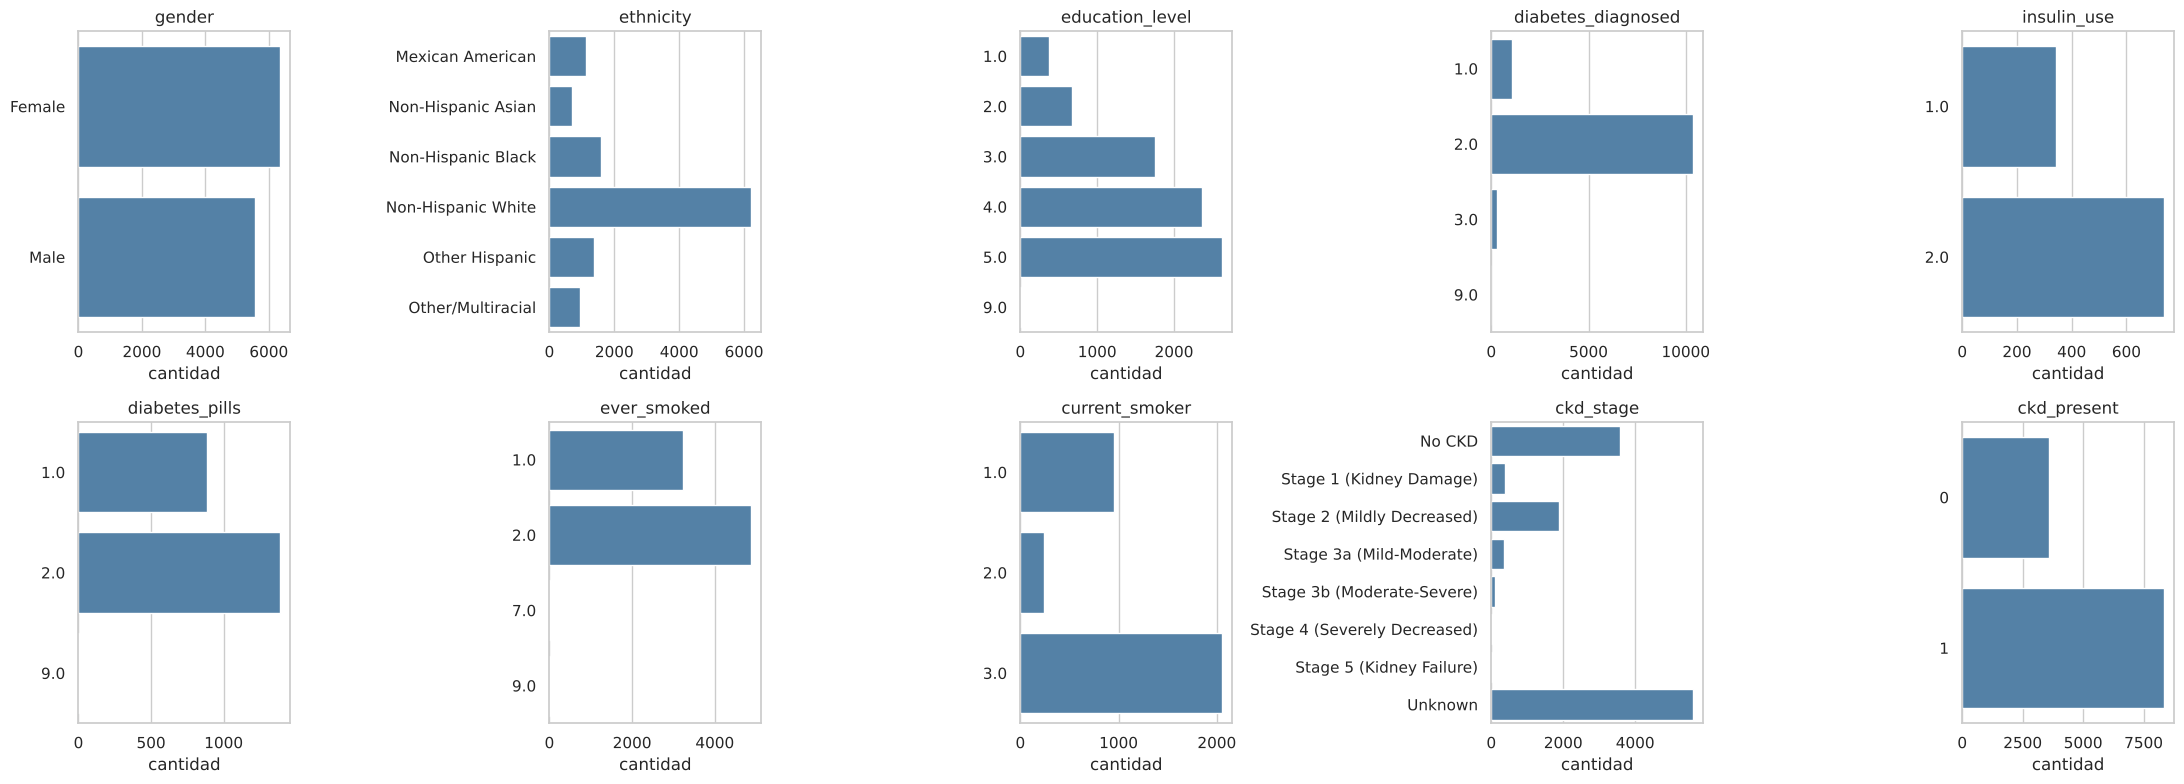

In [ ]:
VARS_CATEGORICAS = ["gender", "ethnicity", "education_level", "diabetes_diagnosed", "insulin_use",
                    "diabetes_pills", "ever_smoked", "current_smoker", "ckd_stage", "ckd_present"]

fig, ejes = plt.subplots(2, 5, figsize=(22, 8))
for eje, col in zip(ejes.ravel(), VARS_CATEGORICAS):
    frecuencias = dataframe[col].value_counts().sort_index()
    sns.barplot(x=frecuencias.values, y=frecuencias.index.astype(str), color="steelblue", ax=eje)
    eje.set_title(col)
    eje.set(xlabel="cantidad", ylabel="")
plt.tight_layout()
plt.show()

## 1.6 Chequeos de consistencia

In [ ]:
# 1) La presión sistólica debe ser mayor que la diastólica
print("Sistólica <= diastólica:", (dataframe["bp_systolic"] <= dataframe["bp_diastolic"]).sum())

# 2) El BMI informado debe coincidir con peso / altura^2
bmi_recalculado = dataframe["weight_kg"] / (dataframe["height_cm"] / 100) ** 2
print("BMI que difiere en más de 0.5 del recalculado:", ((bmi_recalculado - dataframe["bmi"]).abs() > 0.5).sum())

# 3) Relación entre la etapa de CKD y la etiqueta binaria
pd.crosstab(dataframe["ckd_stage"], dataframe["ckd_present"])

Sistólica <= diastólica: 0
BMI que difiere en más de 0.5 del recalculado: 0


ckd_present,0,1
ckd_stage,,
No CKD,3592,0
Stage 1 (Kidney Damage),0,382
Stage 2 (Mildly Decreased),0,1875
Stage 3a (Mild-Moderate),0,341
Stage 3b (Moderate-Severe),0,97
Stage 4 (Severely Decreased),0,28
Stage 5 (Kidney Failure),0,11
Unknown,0,5607


## 1.7 Reporte automático con Sweetviz
Complementa el análisis anterior con un resumen visual de cada variable y de las asociaciones.


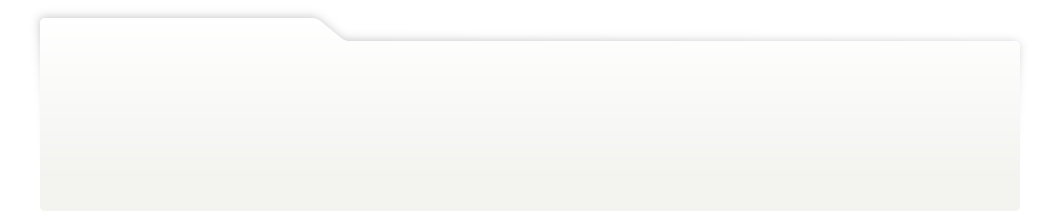
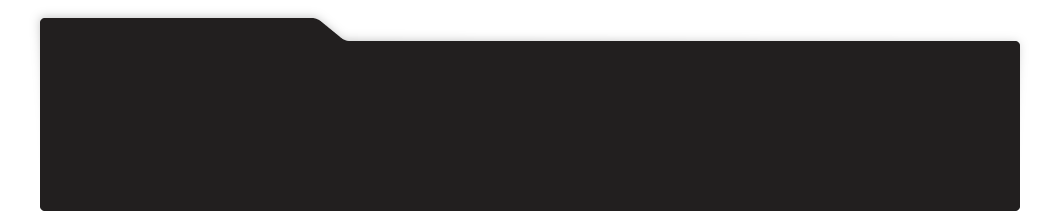
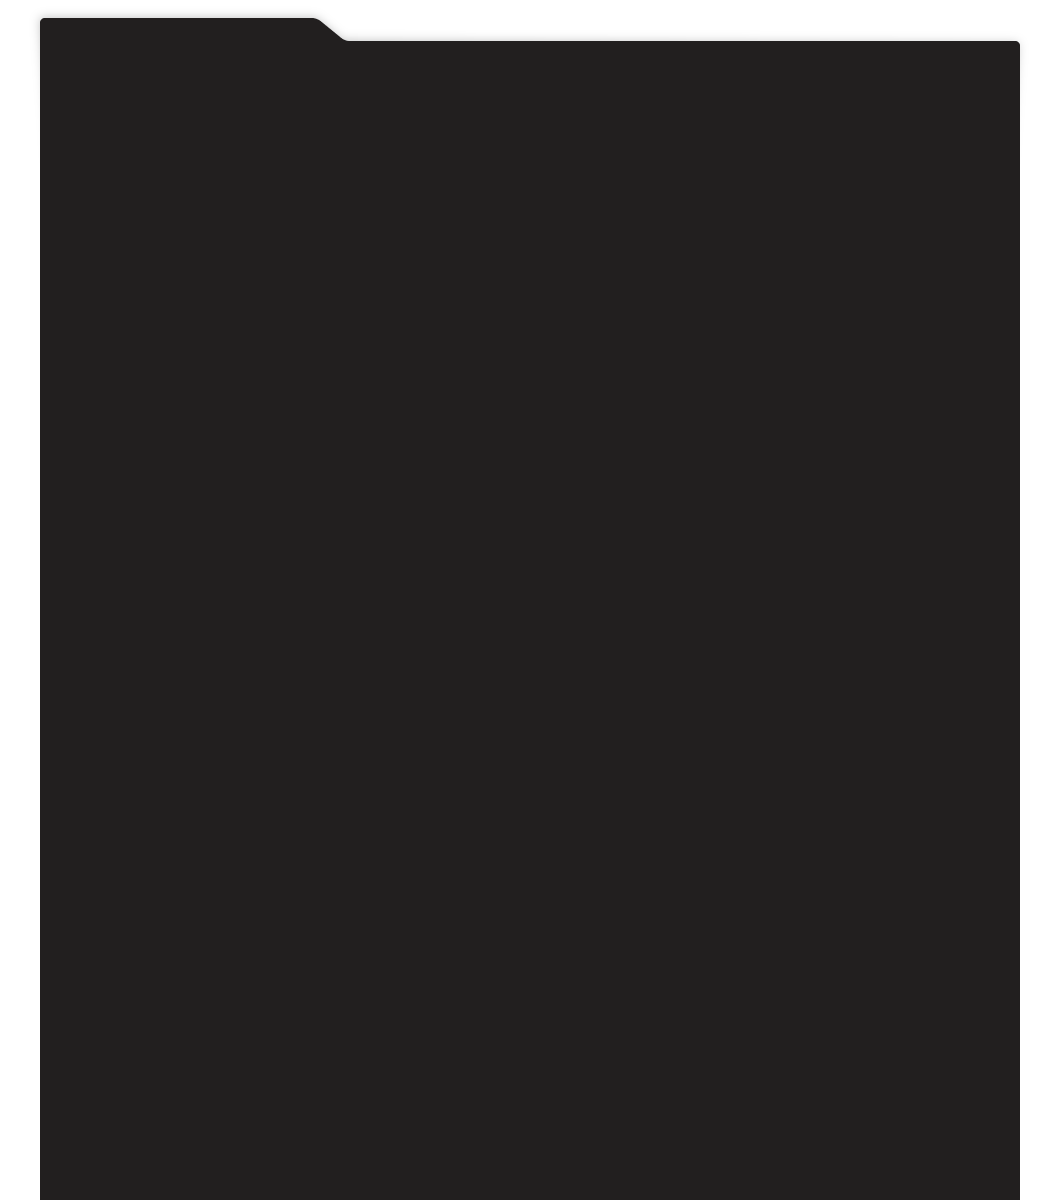
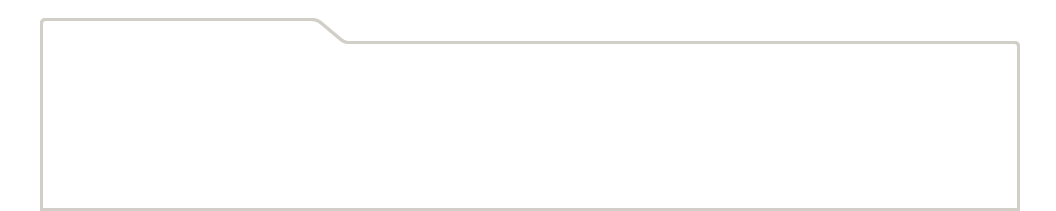
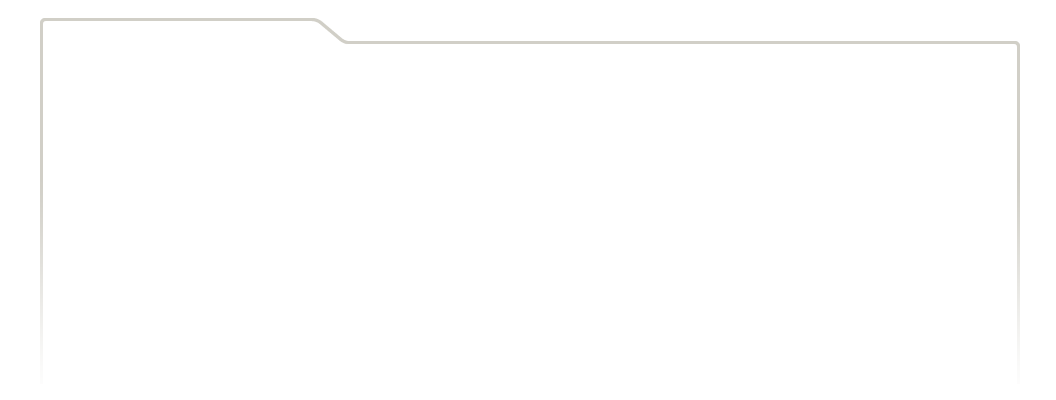
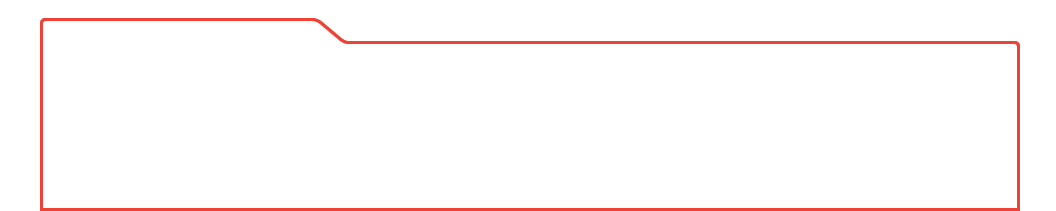
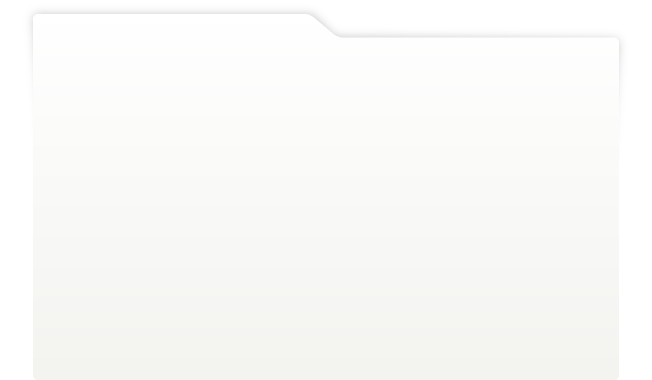
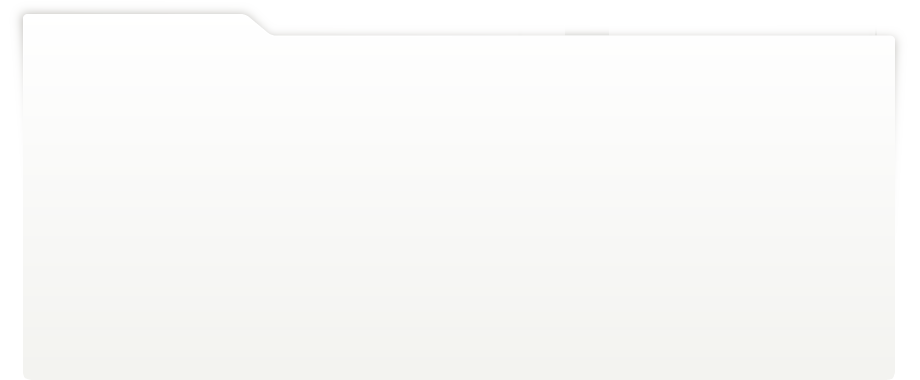
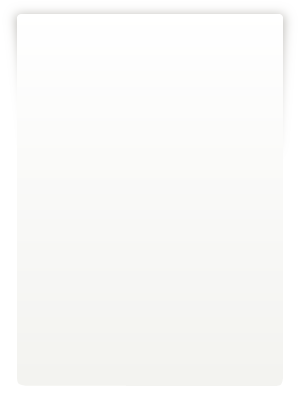
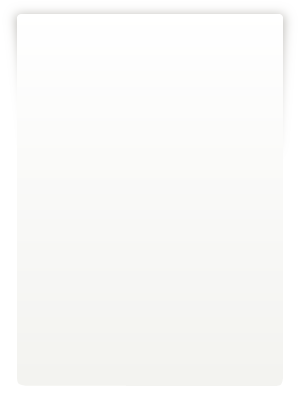
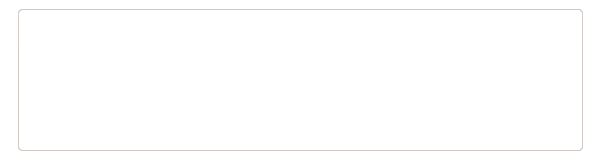
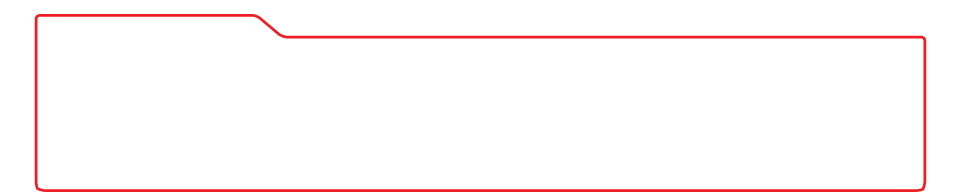
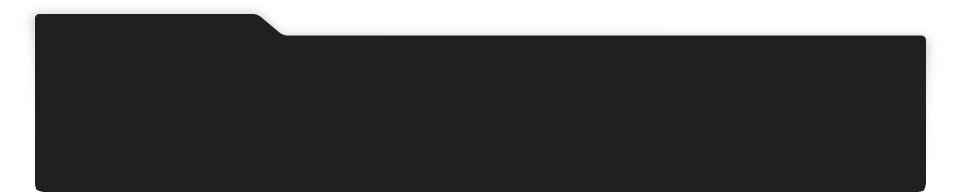
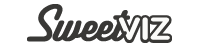
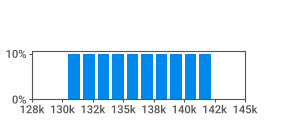
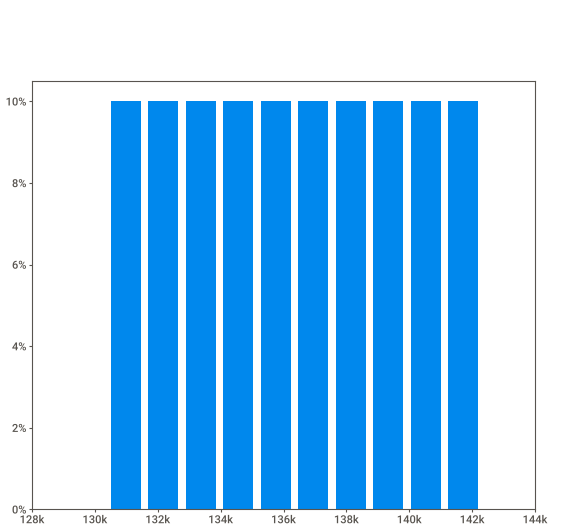
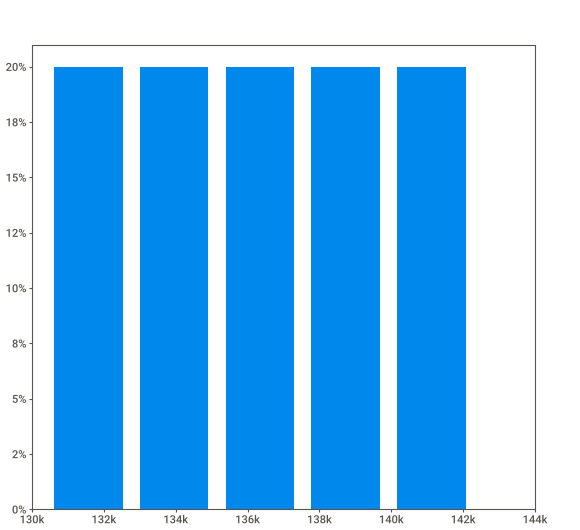
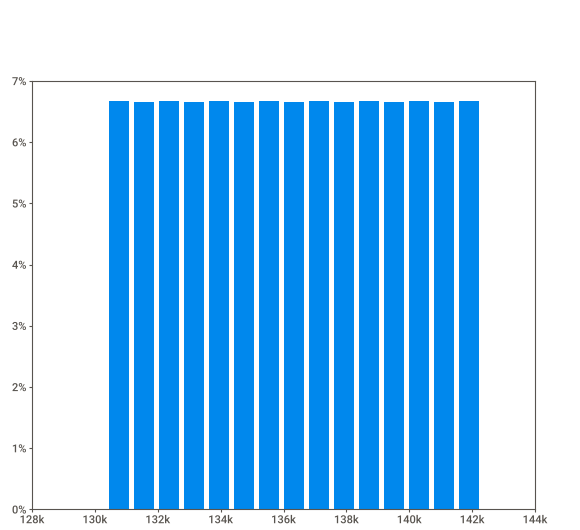
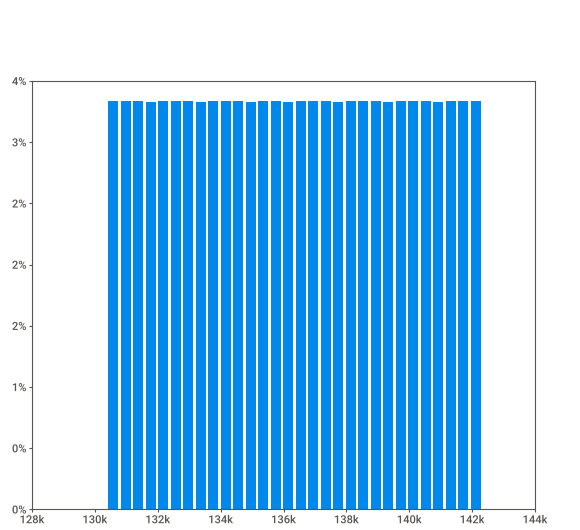
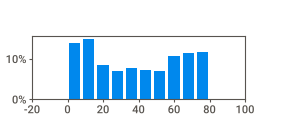
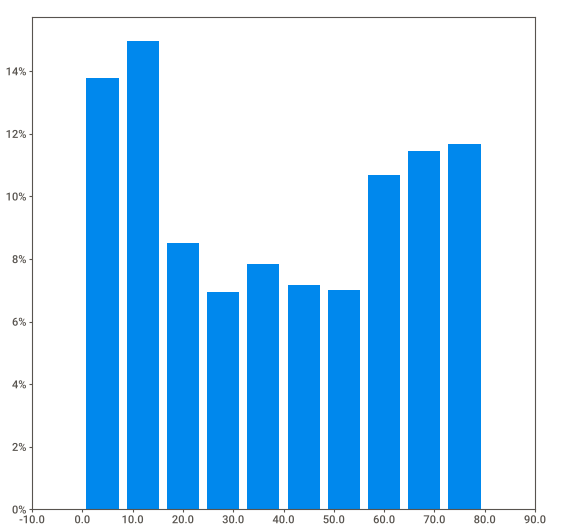
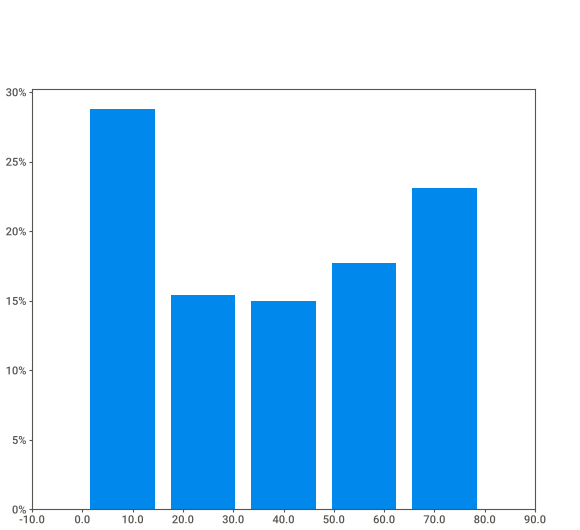
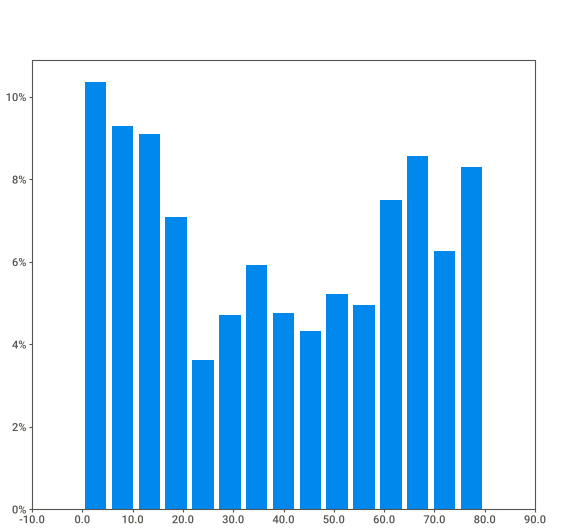
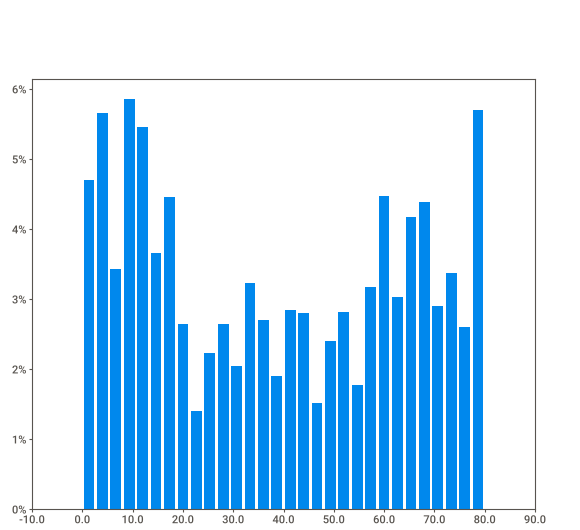
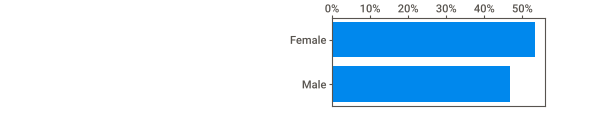
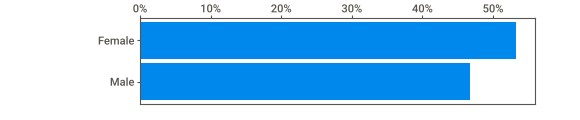
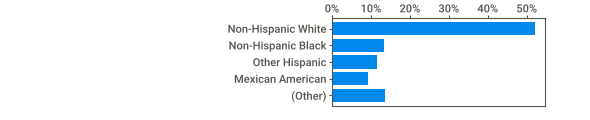
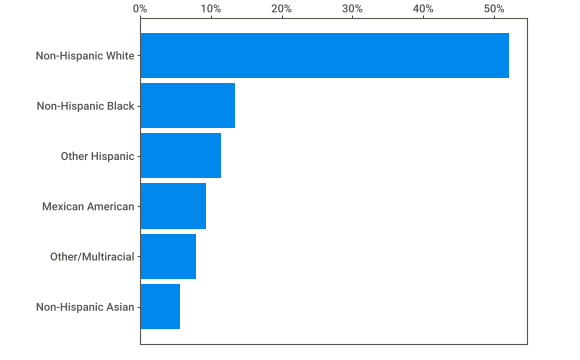
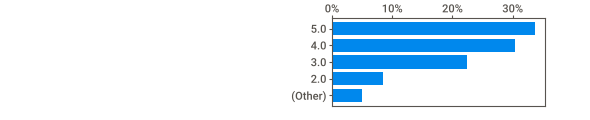
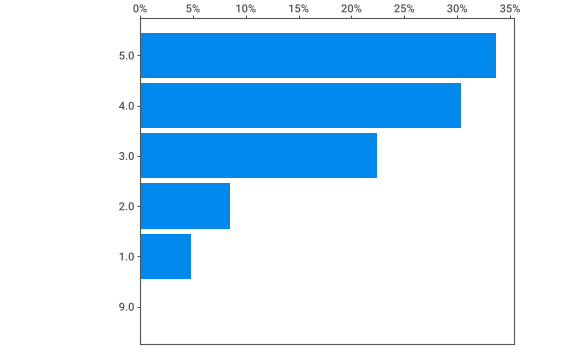
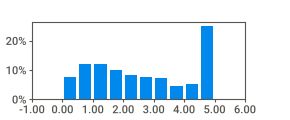
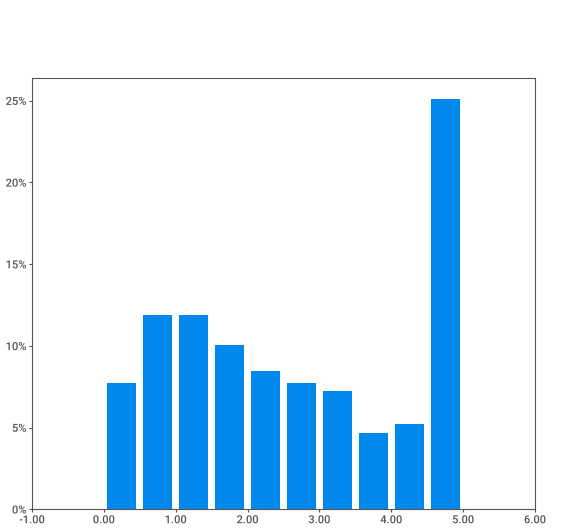
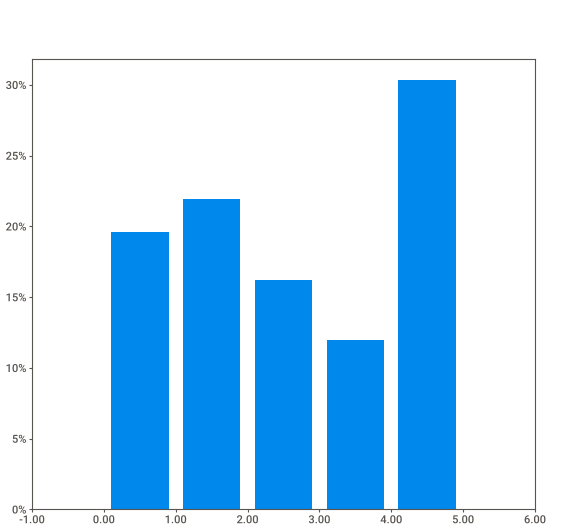
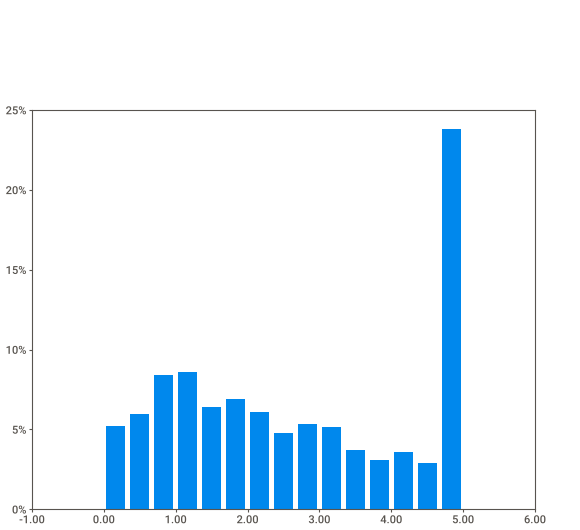
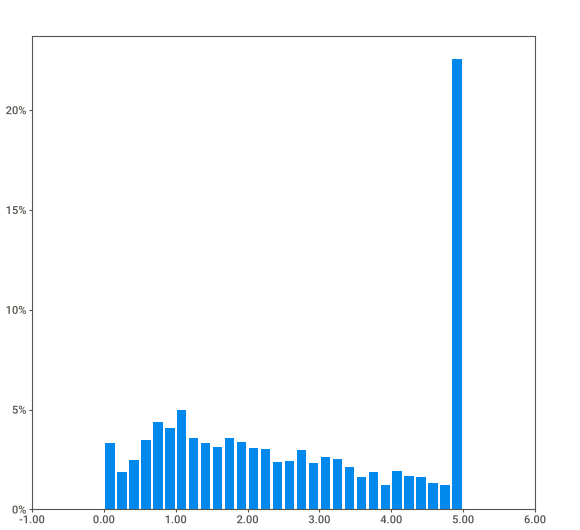
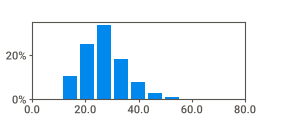
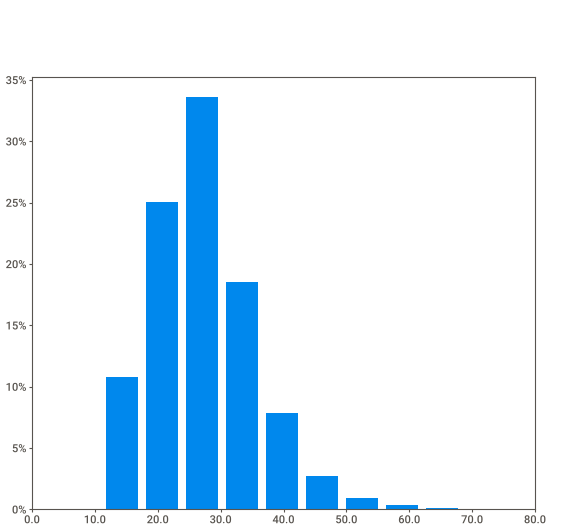
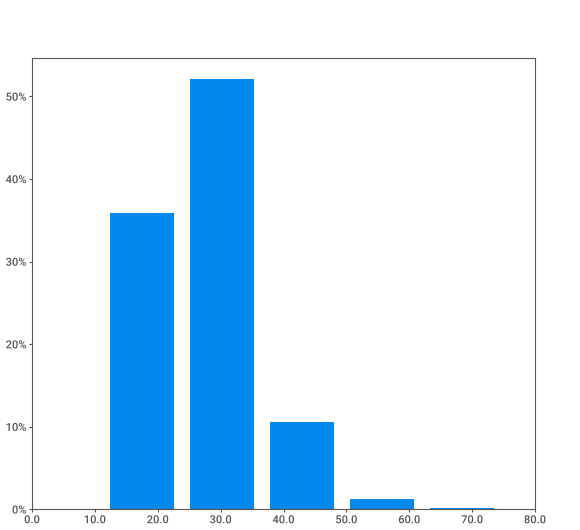
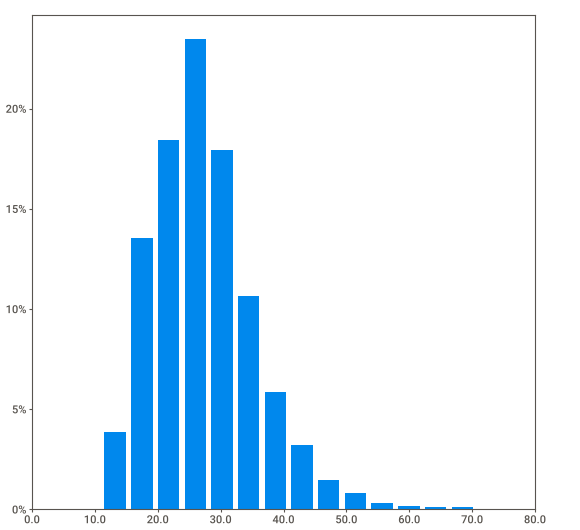
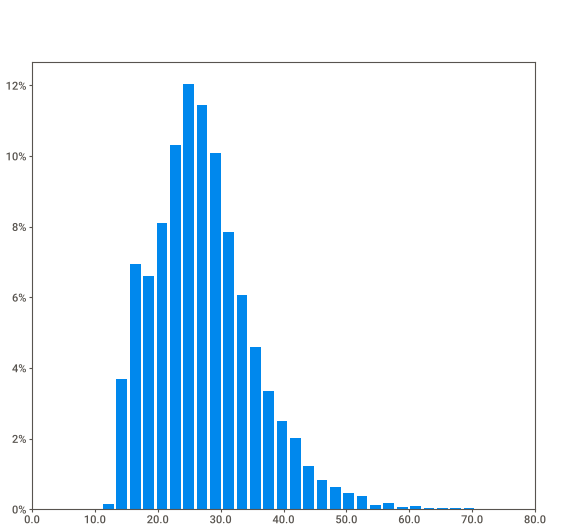
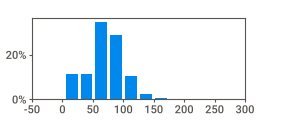
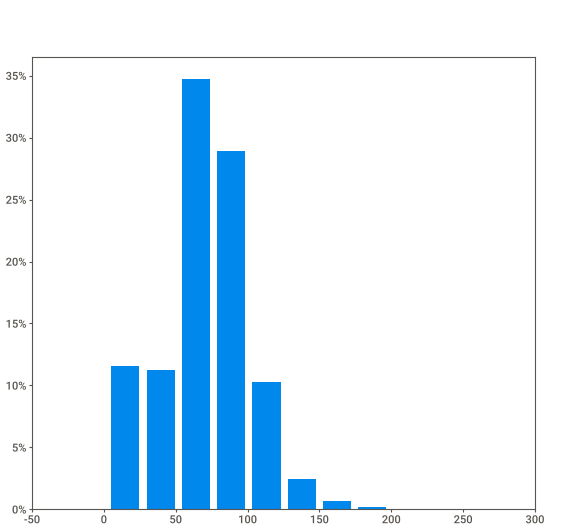
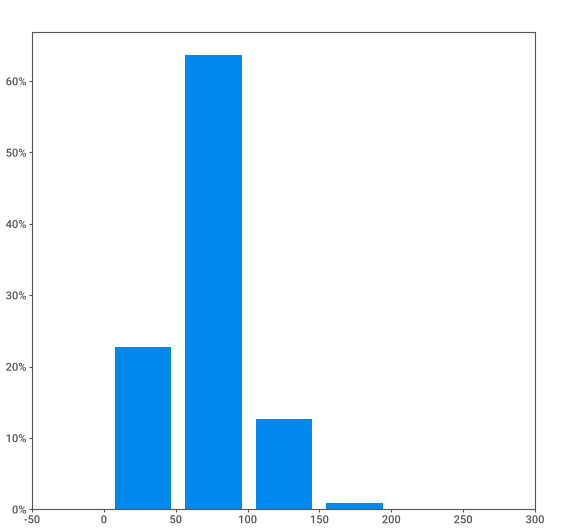
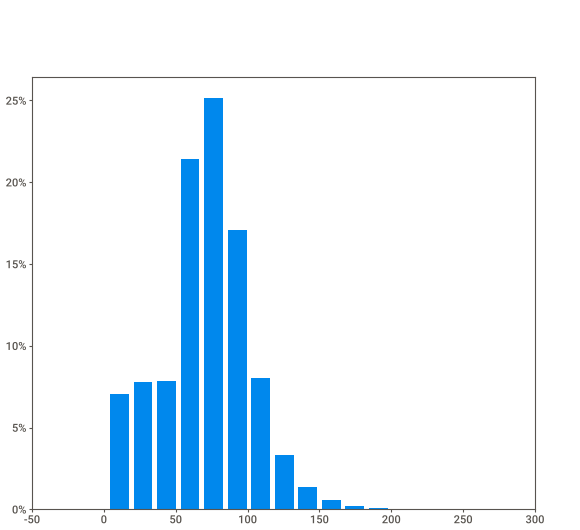
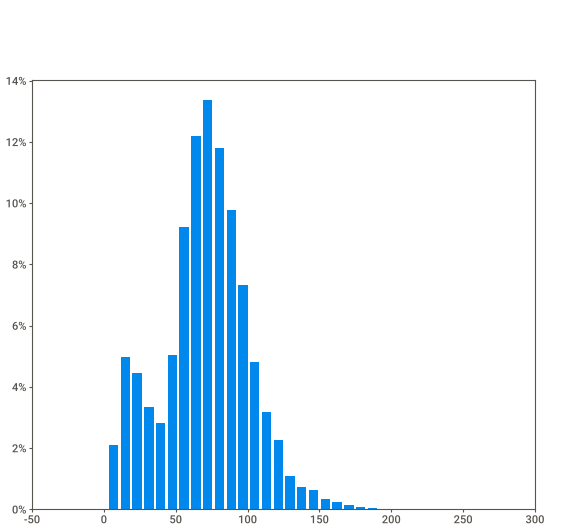
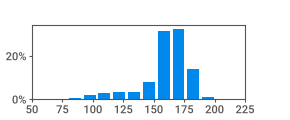
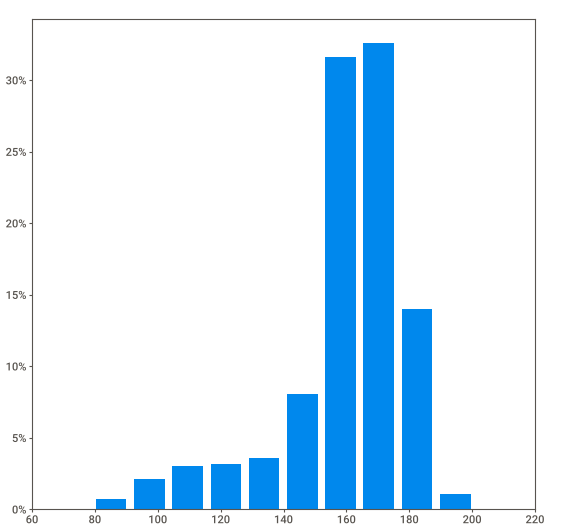
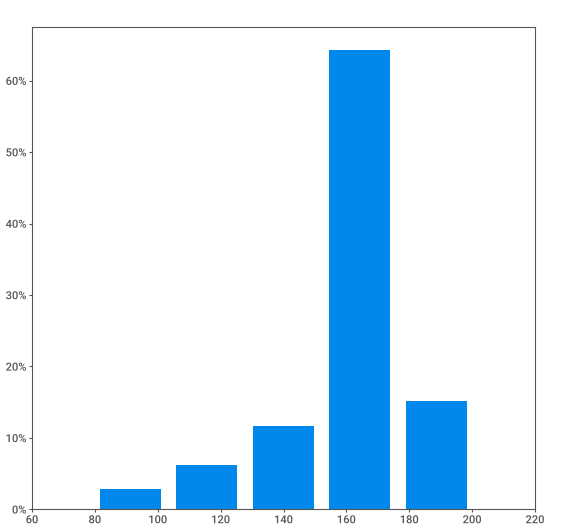
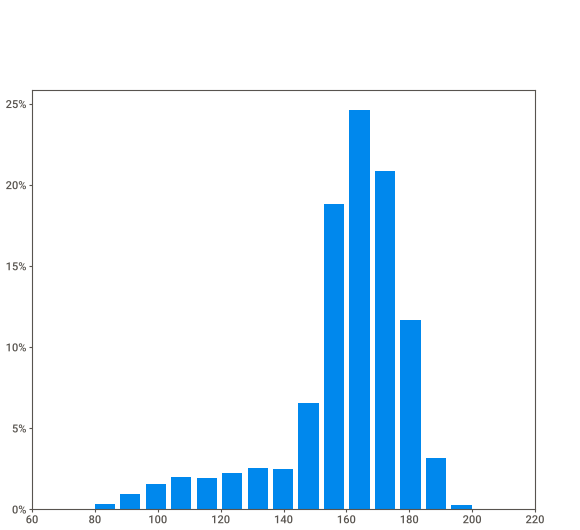
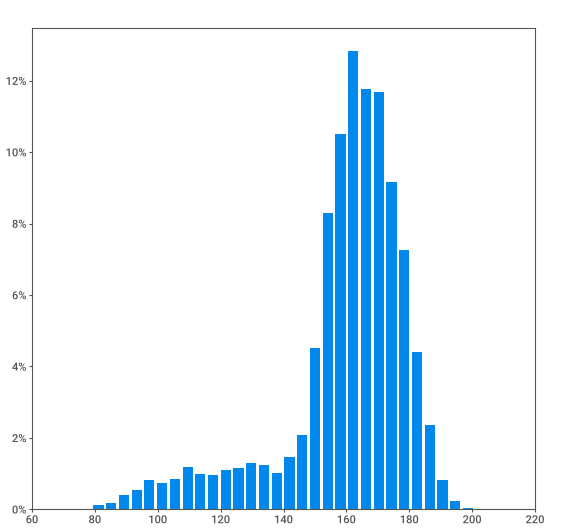
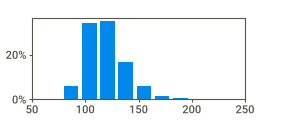
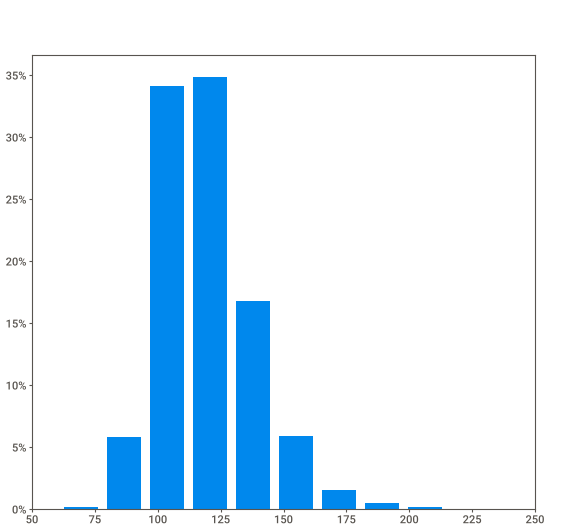
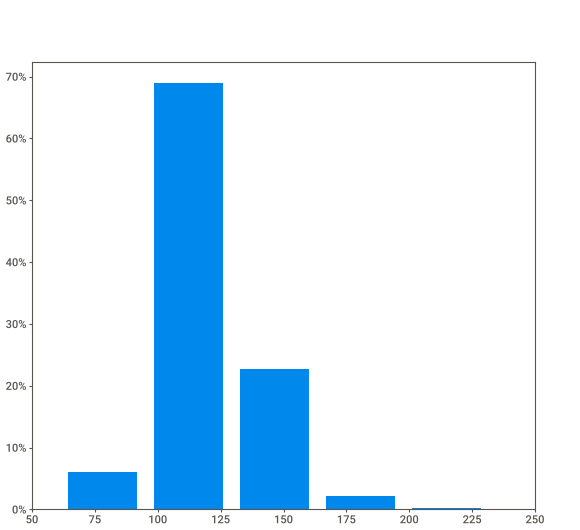
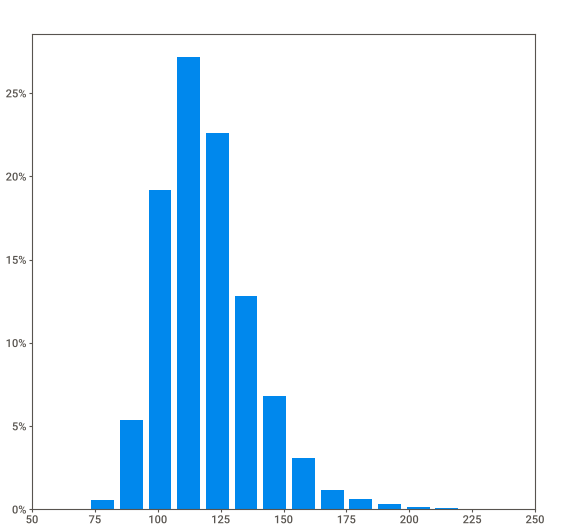
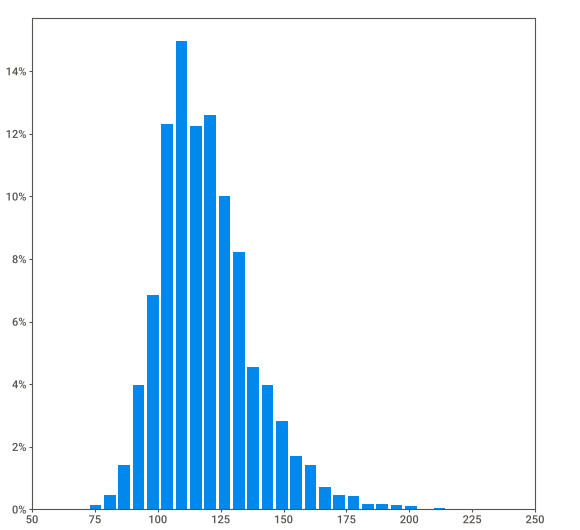
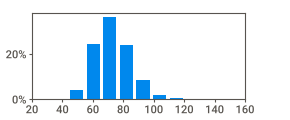
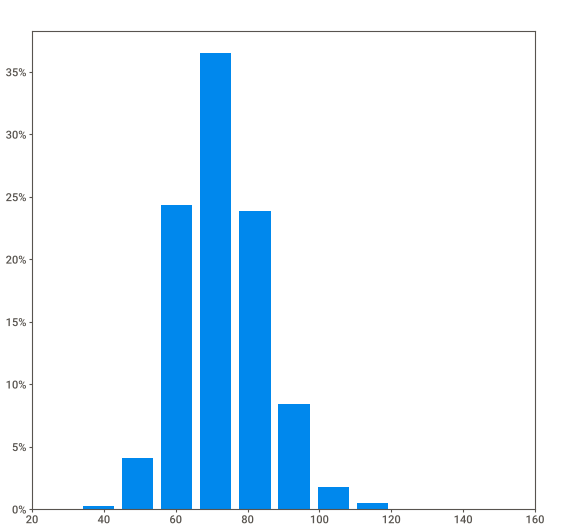
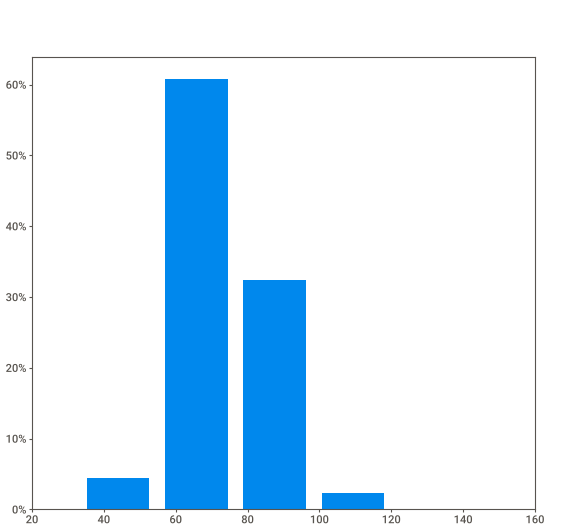
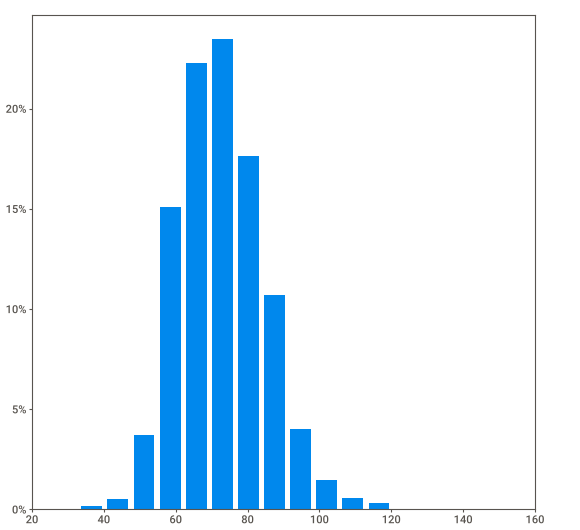
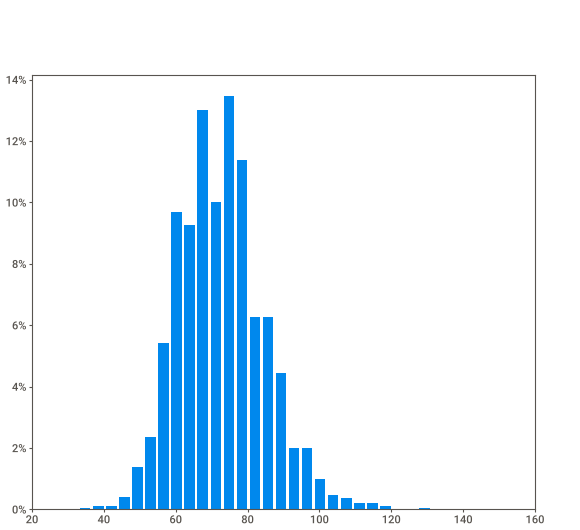
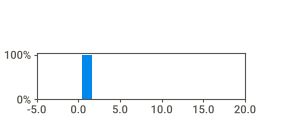
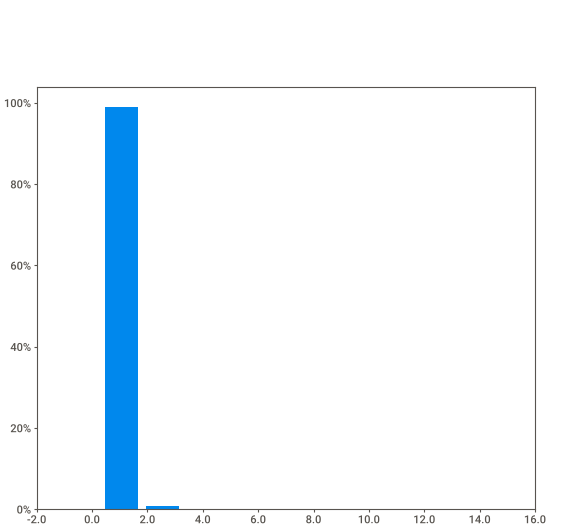
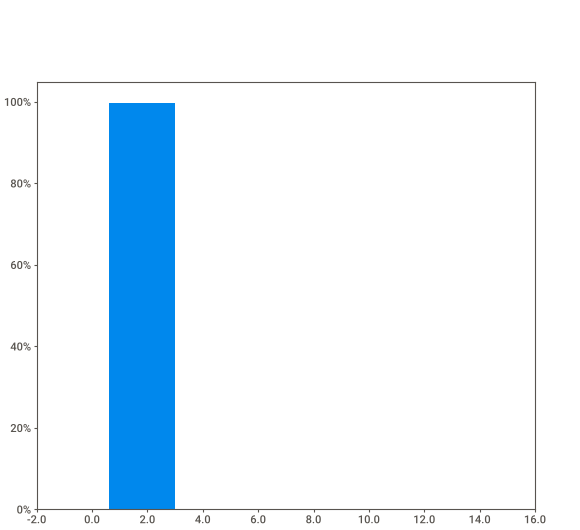
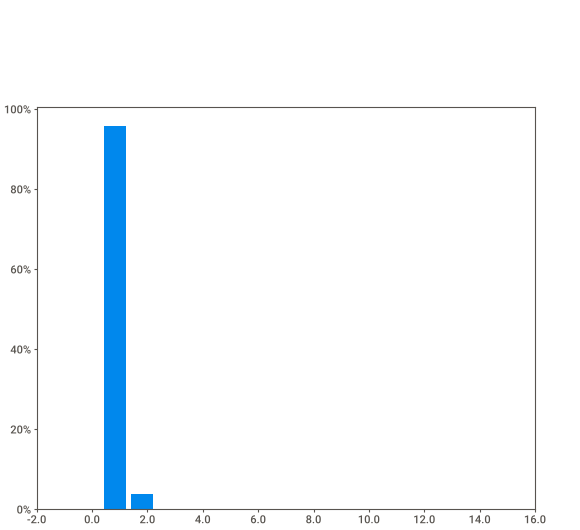
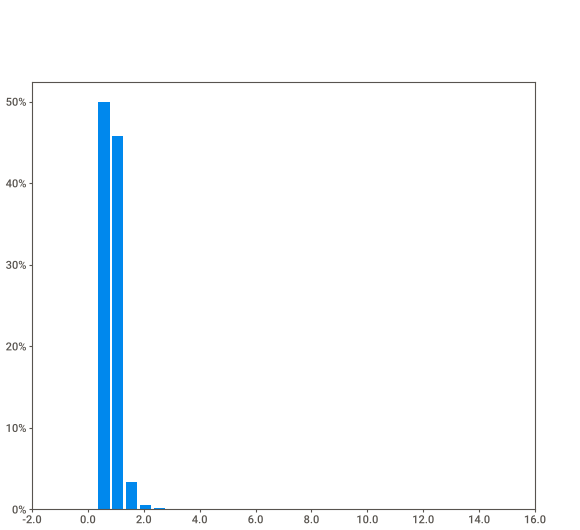
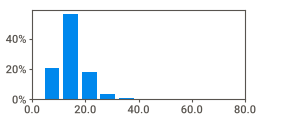
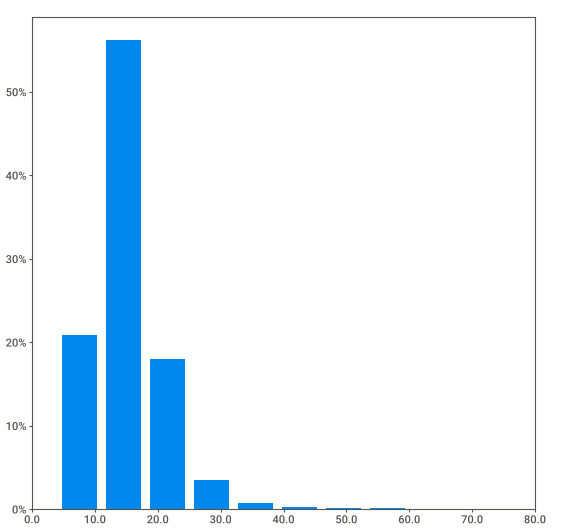
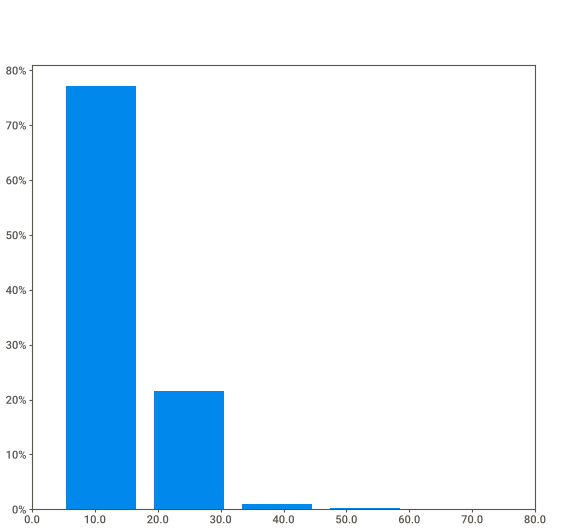
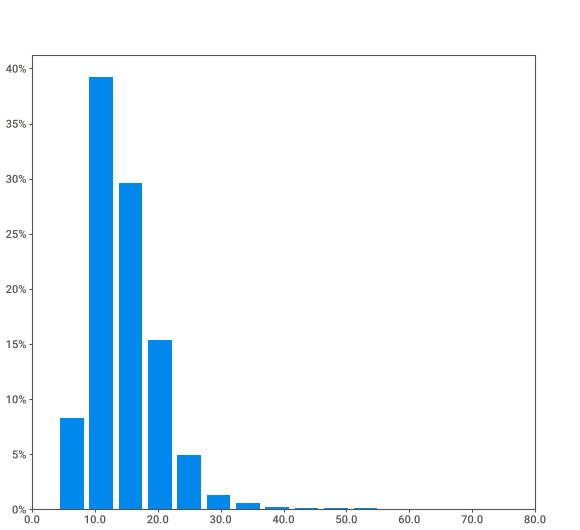
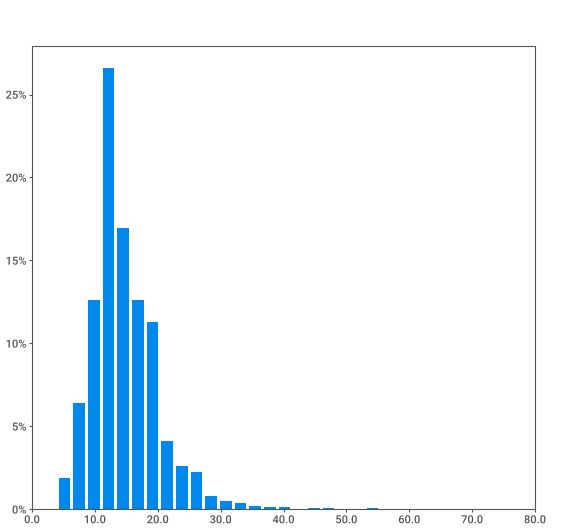
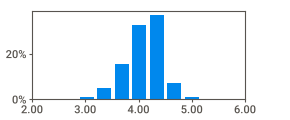
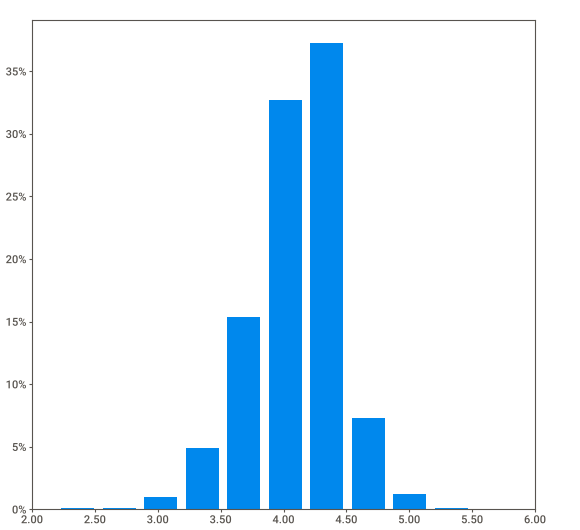
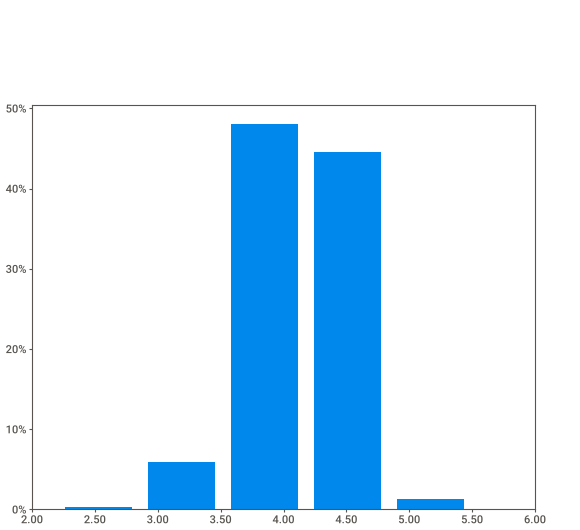
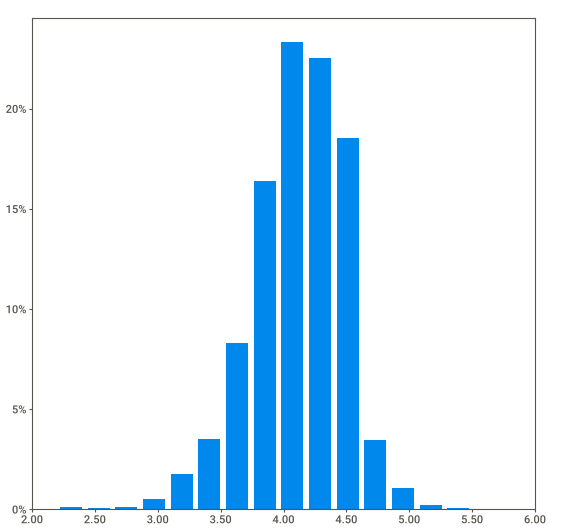
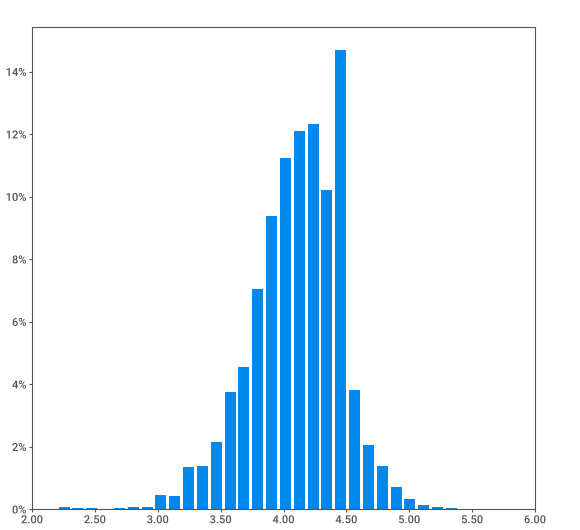
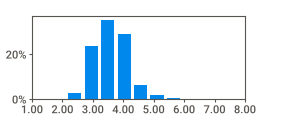
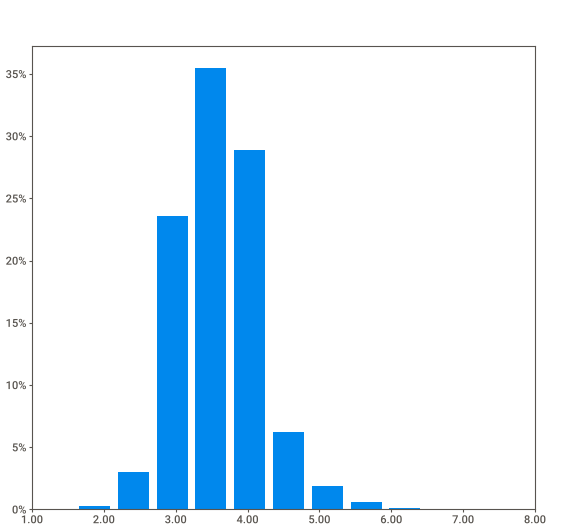
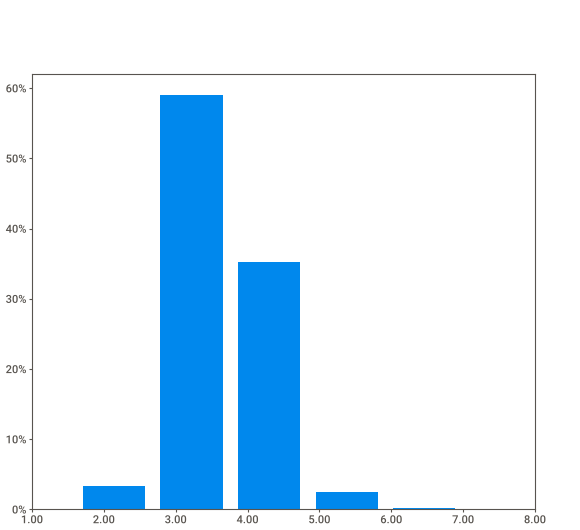
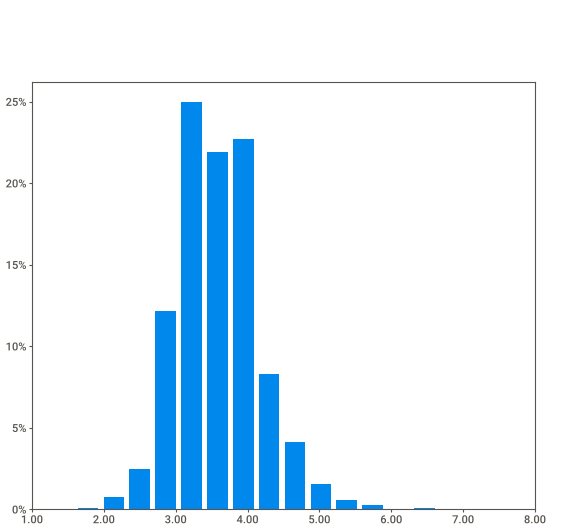
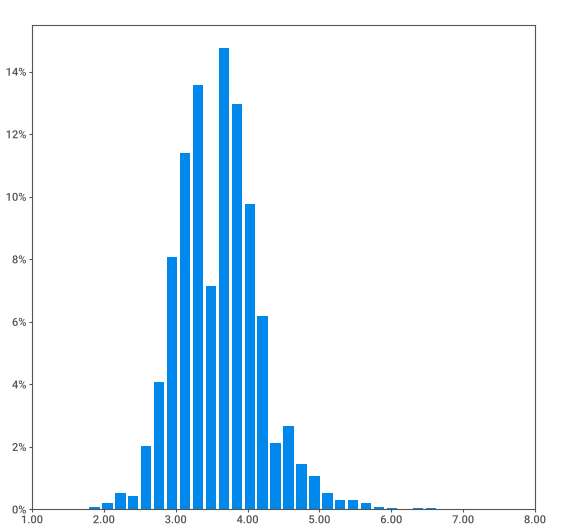
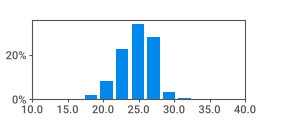
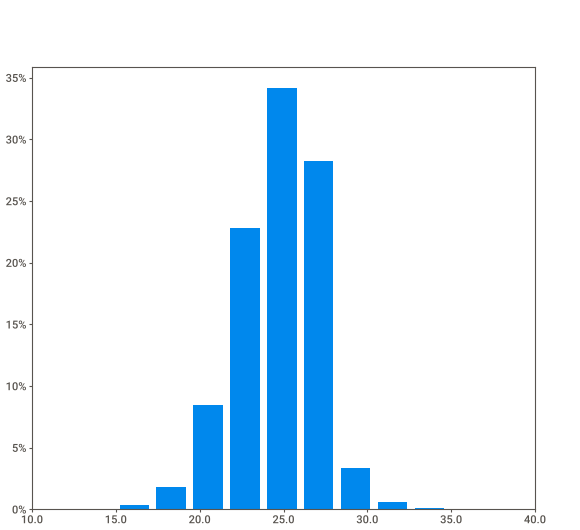
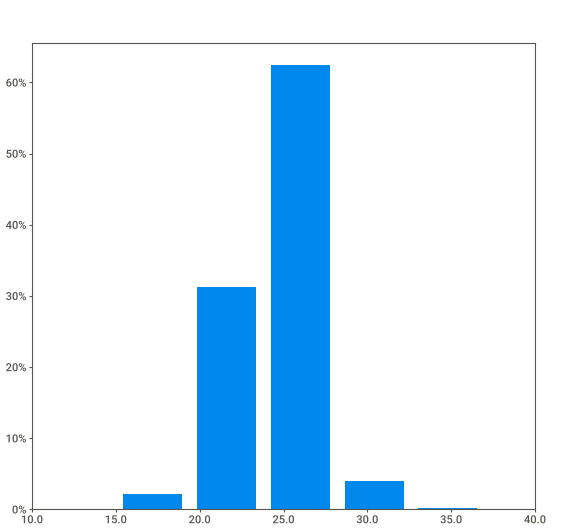
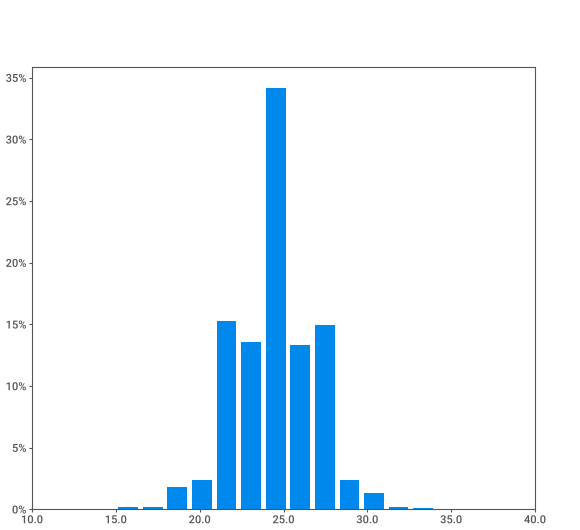
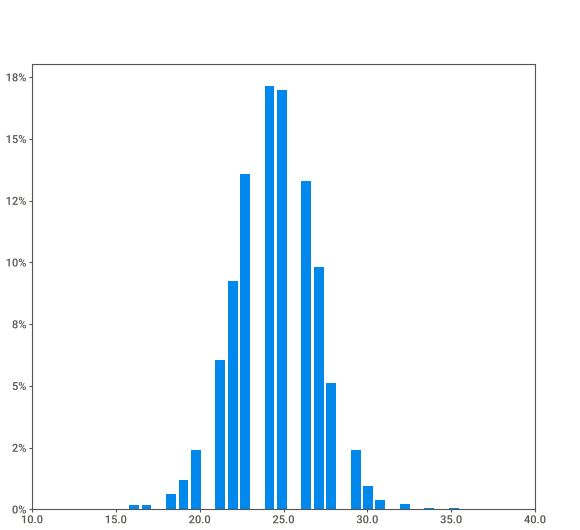
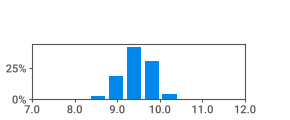
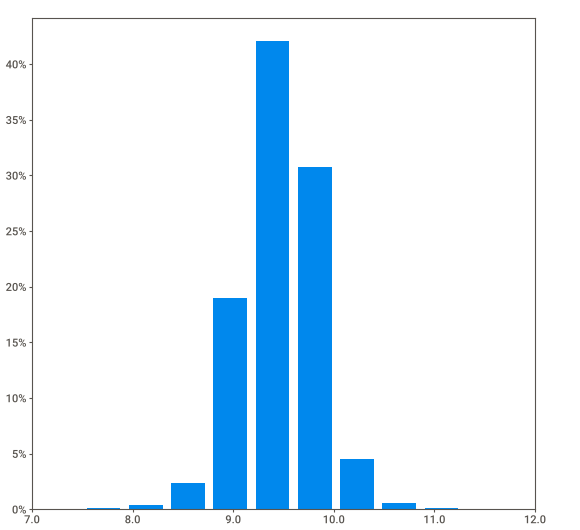
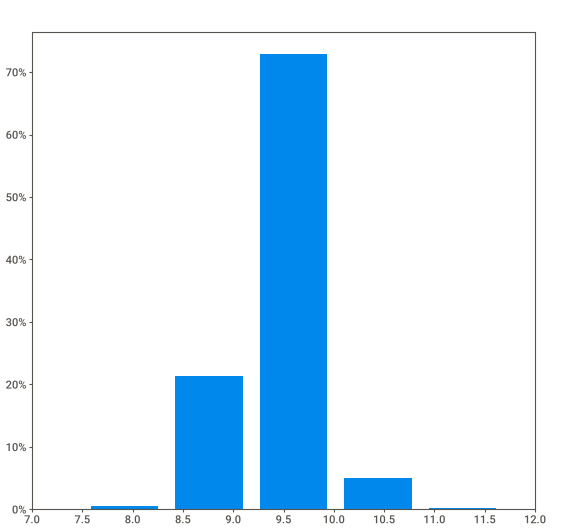
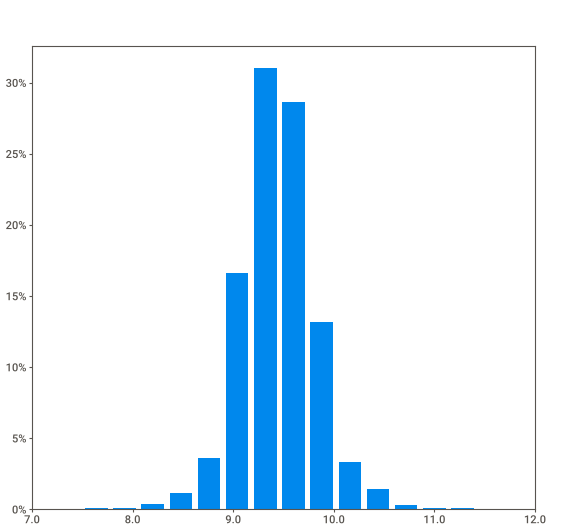
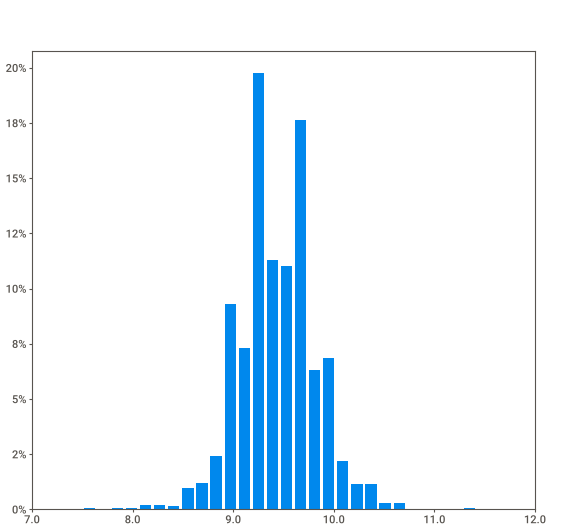
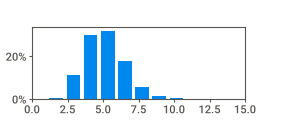
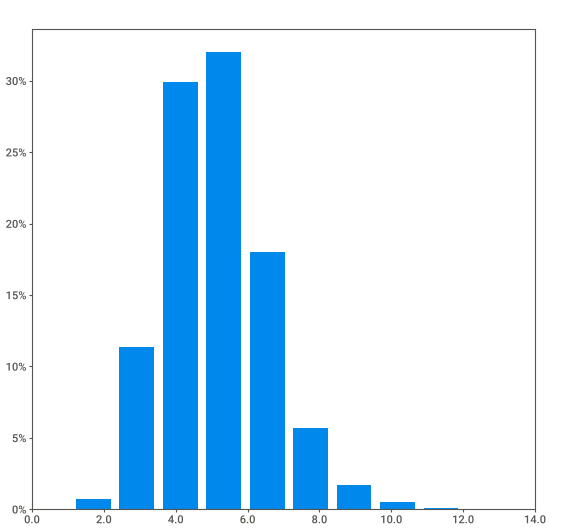
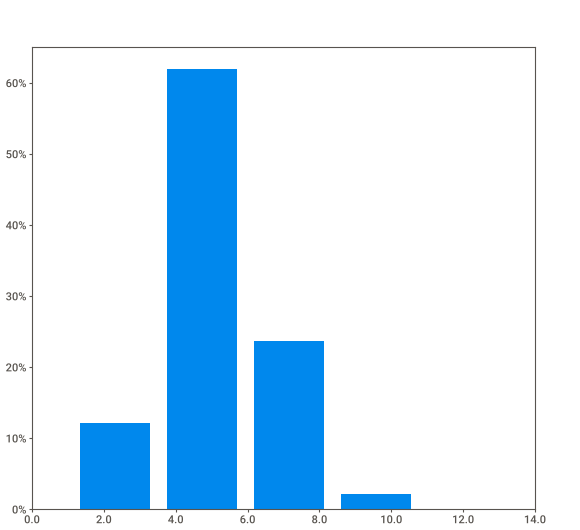
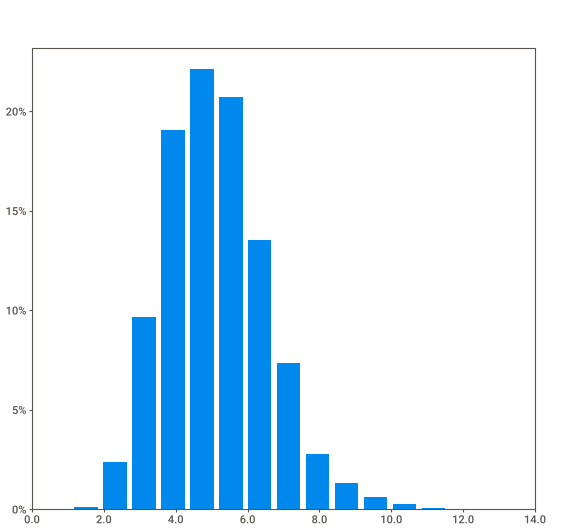
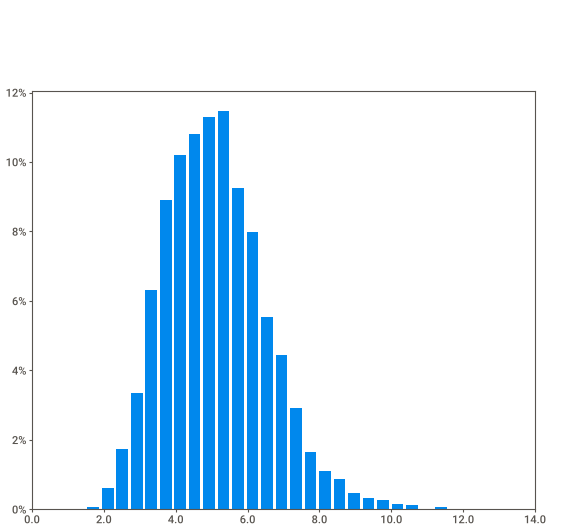
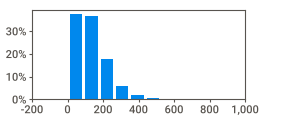
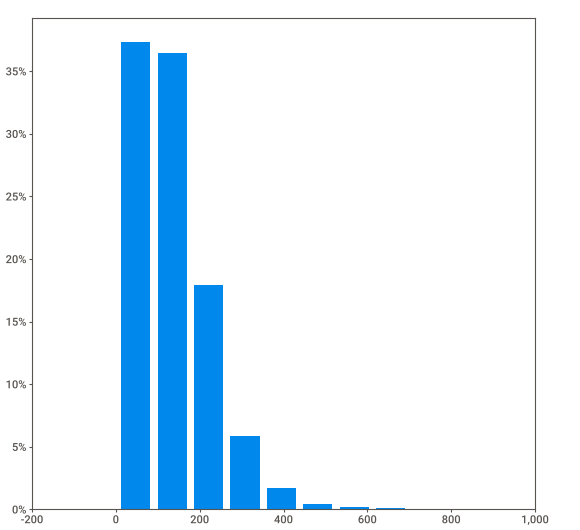
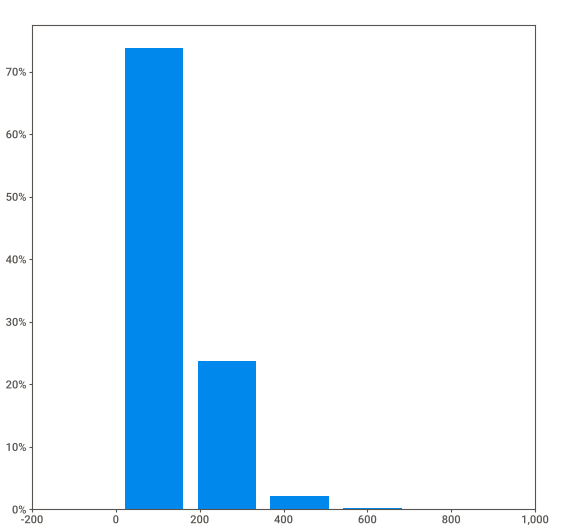
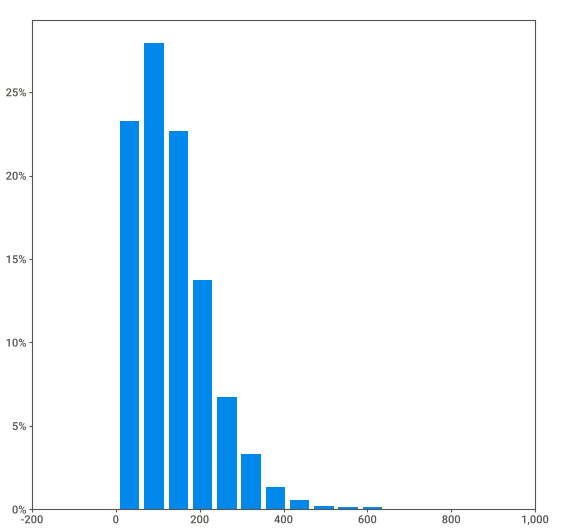
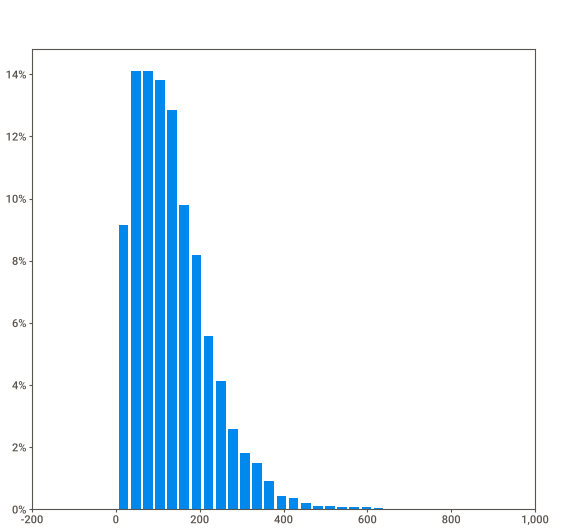
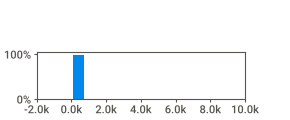
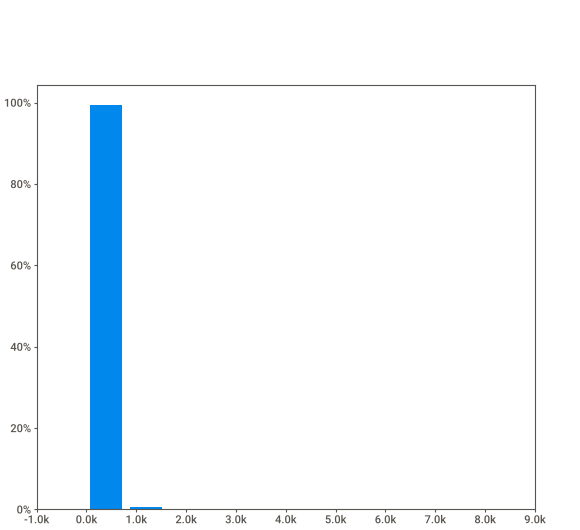
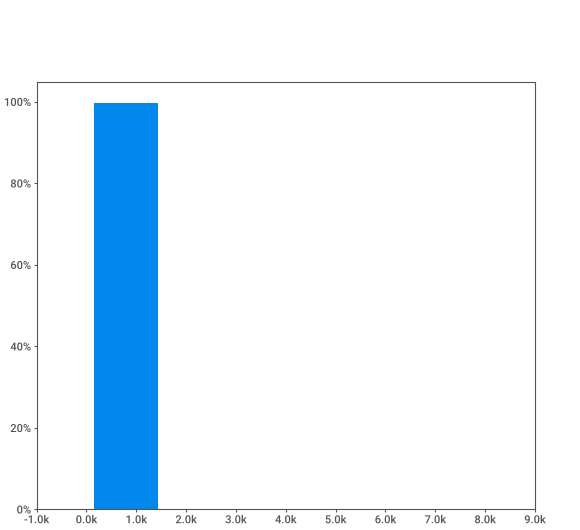
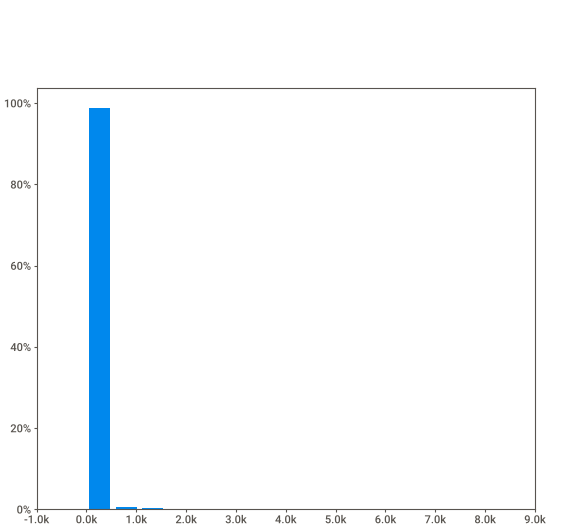
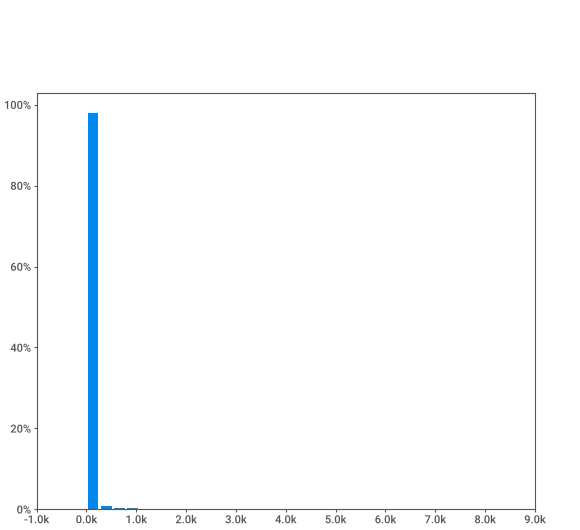
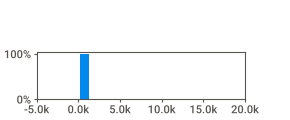
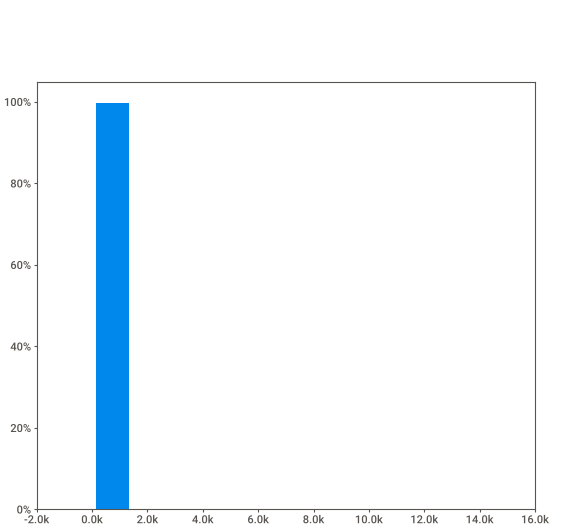
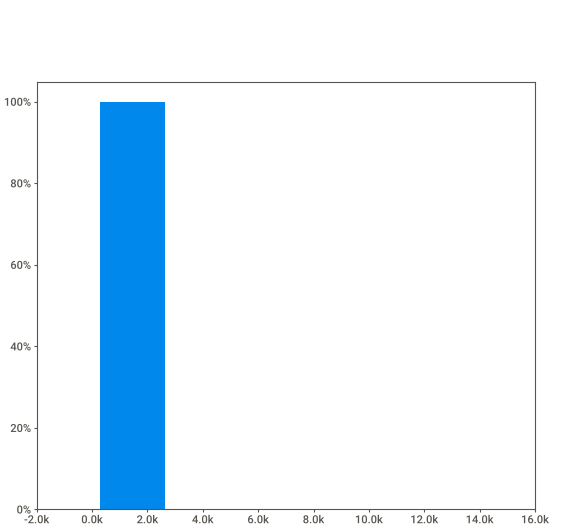
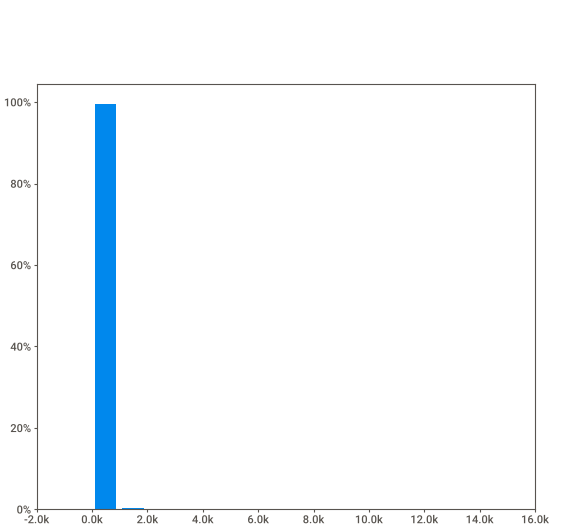
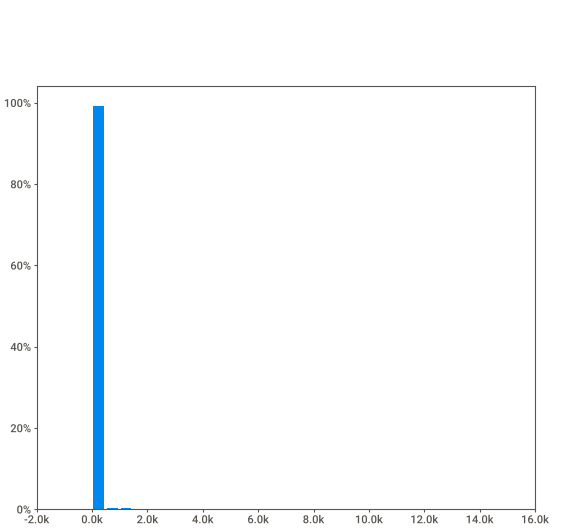
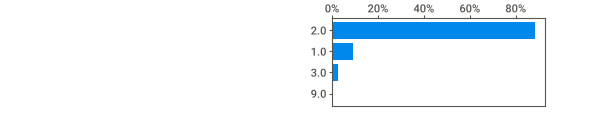
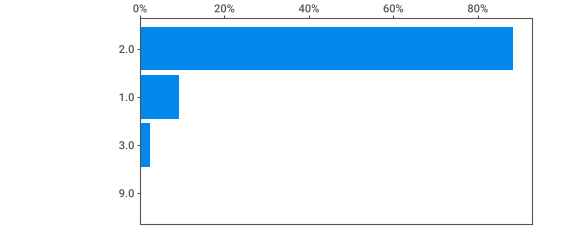
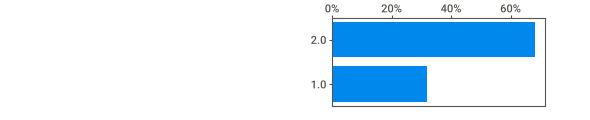
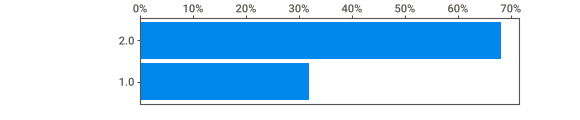
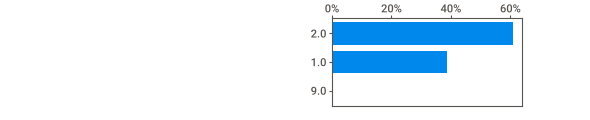
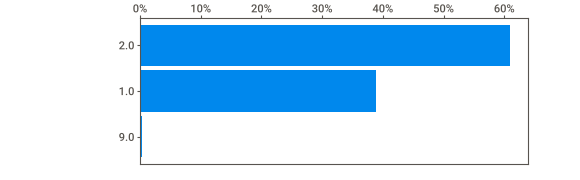
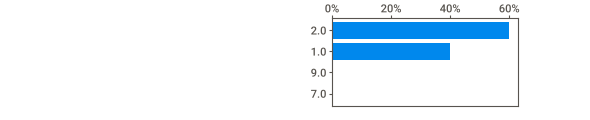
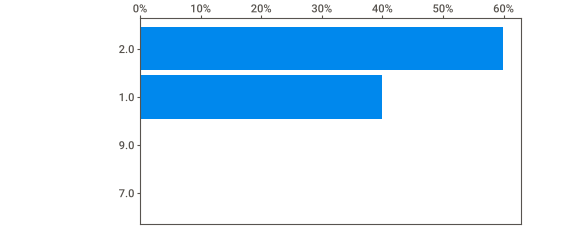
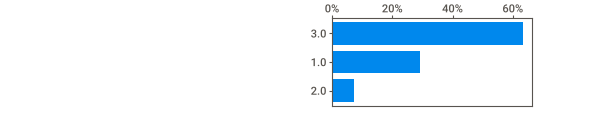
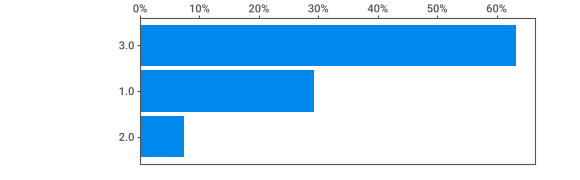
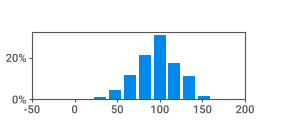
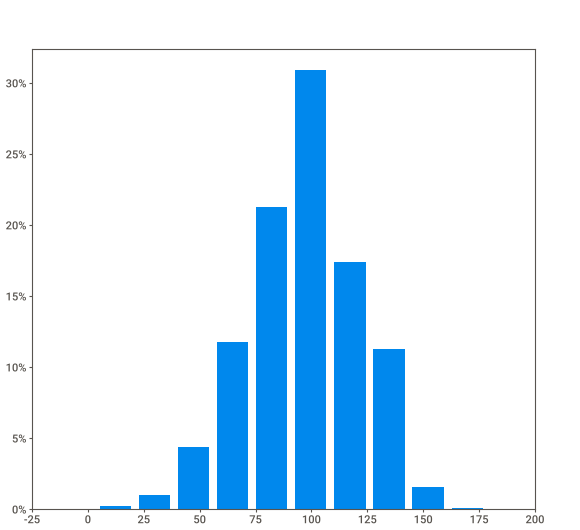
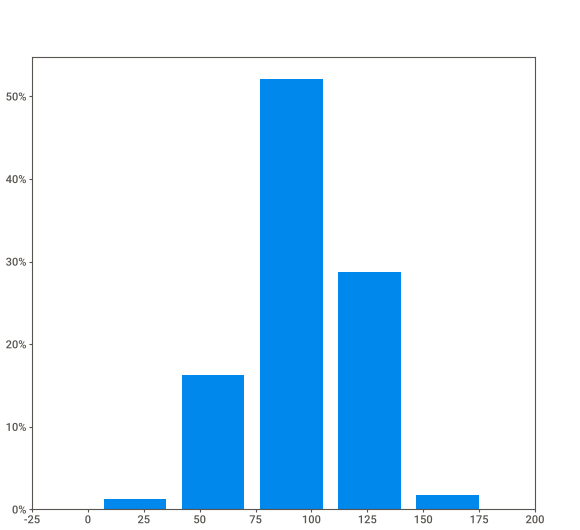
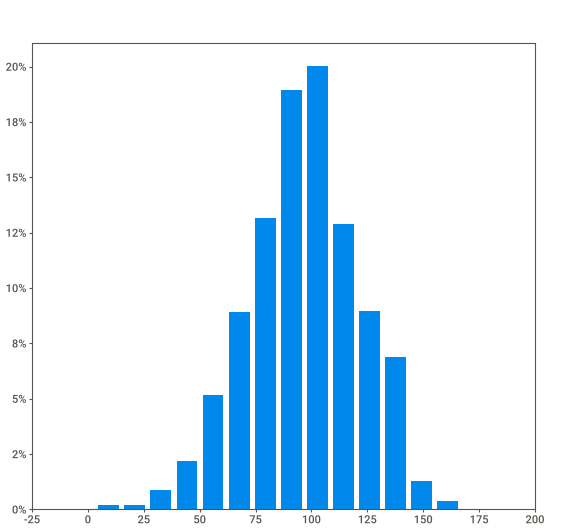
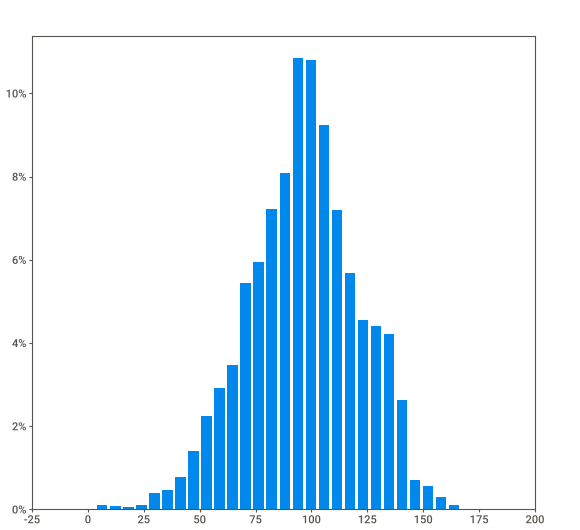
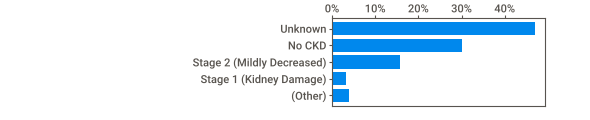
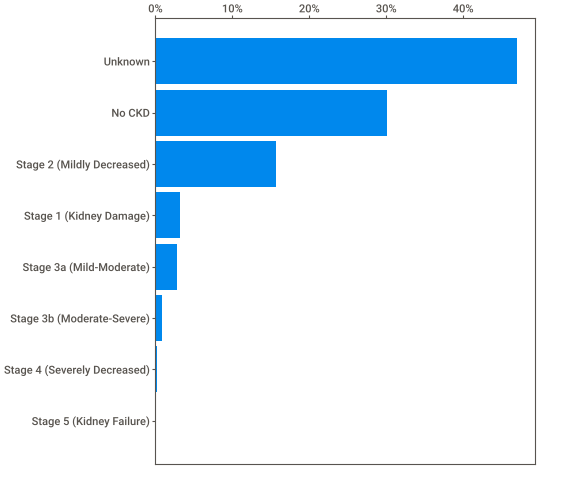
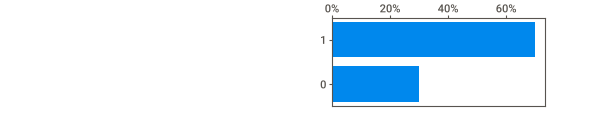
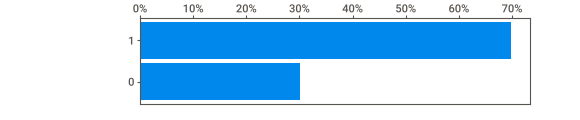
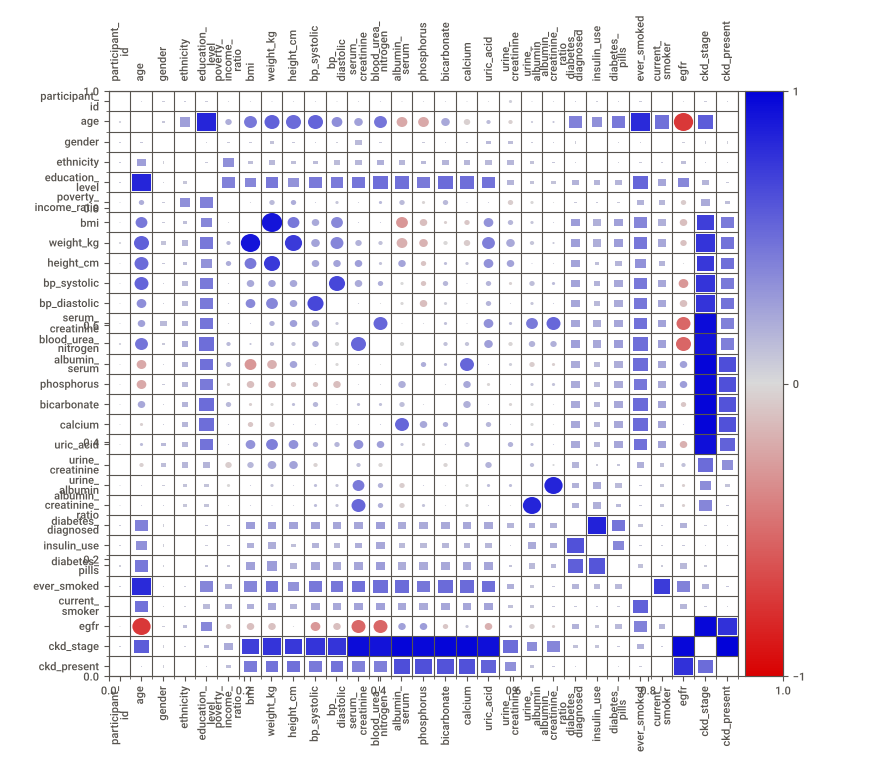
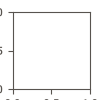

In [ ]:
reporte = sv.analyze(dataframe)
reporte.show_notebook()

# Sweetviz modifica la configuración global de matplotlib (tipografía): se restablece para los gráficos siguientes
plt.rcdefaults()
sns.set_theme(style="whitegrid")

# 2. Limpieza de la base

Se trabaja sobre una copia (`dataframe_limpio`) para conservar la base original. Se busca conservar la mayor cantidad de información posible: no se eliminan registros completos por tener datos faltantes, no se imputan valores, no se eliminan valores extremos (son valores clínicamente posibles) y no se recalcula la `egfr`. Tampoco se escalan variables en esta etapa; esas transformaciones dependen de cada test y se aplican dentro de cada uno.

Las acciones, en orden, son:

1. El texto `Unknown` de `ckd_stage` y los códigos 7 y 9 de las categóricas pasan a `NaN`. Se usa `NaN` y no una categoría *Unknown* para que pandas los excluya automáticamente de los cálculos.
2. `ckd_present` pasa a `NaN` cuando `ckd_stage` es desconocido: no tener información no significa tener la enfermedad (el archivo los codifica como 1).
3. Los ceros de `age` y `poverty_income_ratio`, guardados como ~5e-79 por la conversión del archivo, pasan a 0.
4. Se recodifican las categóricas con los códigos de abajo.
5. Se define la población de análisis (adultos).

**Códigos después de la limpieza** (distintos de los originales):

| Variable | Código | Significado |
| :--- | :---: | :--- |
| `diabetes_diagnosed` | 0 / 1 / 2 | No / Borderline / Sí |
| `insulin_use`, `diabetes_pills`, `ever_smoked` | 0 / 1 | No / Sí |
| `current_smoker` | 0 / 1 / 2 | No fuma actualmente / Fuma algunos días / Fuma todos los días |
| `education_level` | 1 a 5 | Sin cambios |
| `ckd_present` | 0 / 1 | Sin CKD / Con CKD (`NaN` si se desconoce) |

**Nulos estructurales:** `insulin_use`, `diabetes_pills` y `current_smoker` quedan en `NaN` cuando la pregunta no se aplicó (según el antecedente de diabetes o de tabaquismo), y `education_level` y `ever_smoked` cuando la persona es menor de 20 y de 18 años respectivamente. No son datos perdidos y no se imputan.

In [ ]:
dataframe_limpio = dataframe.copy()   # la base original no se modifica

# --- 1. "Unknown" textual y códigos 7 / 9 -> NaN
# Solo ckd_stage tiene texto "Unknown". 7 = "se negó a responder" y 9 = "no sabe".
dataframe_limpio["ckd_stage"] = dataframe_limpio["ckd_stage"].replace("Unknown", np.nan)
dataframe_limpio[VARS_CODIFICADAS] = dataframe_limpio[VARS_CODIFICADAS].replace({7: np.nan, 9: np.nan})

# --- 2. ckd_present: si no se conoce la etapa, no se conoce si hay CKD
dataframe_limpio["ckd_present"] = dataframe_limpio["ckd_present"].astype(float)   # float para admitir NaN
dataframe_limpio.loc[dataframe_limpio["ckd_stage"].isna(), "ckd_present"] = np.nan

# --- 3. Ceros guardados como números diminutos (~5e-79)
for col in ["age", "poverty_income_ratio"]:
    cantidad = (dataframe_limpio[col] < 1e-6).sum()
    dataframe_limpio.loc[dataframe_limpio[col] < 1e-6, col] = 0
    print(f"{col}: {cantidad} valores corregidos a 0")
dataframe_limpio["age"] = dataframe_limpio["age"].astype(int)

# --- 4. Recodificación de categóricas (replace con diccionario aplica todos los cambios a la vez)
# Original: 1 = Sí, 2 = No, 3 = Borderline  ->  Nuevo: 0 = No, 1 = Borderline, 2 = Sí
dataframe_limpio["diabetes_diagnosed"] = dataframe_limpio["diabetes_diagnosed"].replace({1: 2, 2: 0, 3: 1})

# Original: 1 = Sí, 2 = No  ->  Nuevo: 0 = No, 1 = Sí
for col in ["insulin_use", "diabetes_pills", "ever_smoked"]:
    dataframe_limpio[col] = dataframe_limpio[col].replace({1: 1, 2: 0})

# Original: 1 = todos los días, 2 = algunos días, 3 = no fuma  ->  Nuevo: 2, 1, 0
dataframe_limpio["current_smoker"] = dataframe_limpio["current_smoker"].replace({1: 2, 2: 1, 3: 0})

# Verificación de dimensiones y de las categorías resultantes
print("\nDimensiones:", dataframe.shape, "->", dataframe_limpio.shape)
for col in ["diabetes_diagnosed", "insulin_use", "diabetes_pills", "ever_smoked", "current_smoker", "ckd_present"]:
    print(f"\n{col}:\n{dataframe_limpio[col].value_counts(dropna=False).sort_index().to_string()}")

age: 189 valores corregidos a 0
poverty_income_ratio: 100 valores corregidos a 0

Dimensiones: (11933, 29) -> (11933, 29)

diabetes_diagnosed:
diabetes_diagnosed
0.0    10371
1.0      284
2.0     1081
NaN      197

insulin_use:
insulin_use
0.0      737
1.0      344
NaN    10852

diabetes_pills:
diabetes_pills
0.0    1389
1.0     885
NaN    9659

ever_smoked:
ever_smoked
0.0    4878
1.0    3243
NaN    3812

current_smoker:
current_smoker
0.0    2053
1.0     238
2.0     952
NaN    8690

ckd_present:
ckd_present
0.0    3592
1.0    2734
NaN    5607


## 2.1 Población de análisis: adultos
Los nulos restantes se concentran en los menores de edad (Sección 1.3). Además, la ecuación CKD-EPI 2021 con la que se calcula la `egfr` y los umbrales KDIGO están definidos para adultos, y el BMI no es comparable entre niños y adultos. Por eso las hipótesis se evalúan sobre personas de 18 años o más. El umbral es un parámetro: con `EDAD_MINIMA = 0` se usa toda la base.

In [ ]:
EDAD_MINIMA = 18
df_adultos = dataframe_limpio[dataframe_limpio["age"] >= EDAD_MINIMA].copy()
print(f"Participantes en la base: {len(dataframe_limpio)} | adultos (población de análisis): {len(df_adultos)}")

# Nulos que quedan entre los adultos (corresponden a quienes no hicieron el examen o los análisis, y a no respuestas puntuales)
(pd.DataFrame({"cantidad": df_adultos.isna().sum(), "porcentaje": (df_adultos.isna().mean() * 100).round(2)})
   .query("cantidad > 0").sort_values("porcentaje", ascending=False))

Participantes en la base: 11933 | adultos (población de análisis): 8153


,cantidad,porcentaje
insulin_use,7080,86.84
diabetes_pills,5931,72.75
current_smoker,4910,60.22
phosphorus,2499,30.65
egfr,2495,30.60
ckd_stage,2495,30.60
ckd_present,2495,30.60
bicarbonate,2495,30.60
serum_creatinine,2495,30.60
blood_urea_nitrogen,2494,30.59


**Tratamiento de los nulos restantes:** no se imputan. La `egfr` y `ckd_present` (variable resultado) no deben imputarse, y los análisis de laboratorio faltan por diseño de la encuesta. Cada hipótesis se evalúa con los **casos completos** de las variables que usa; la función de abajo informa cuántos se descartan.

In [ ]:
def casos_completos(df, columnas):
    """Devuelve las filas sin nulos en `columnas` e informa cuántas se descartan."""
    completos = df.dropna(subset=columnas)
    print(f"Casos completos: {len(completos)} de {len(df)} filas ({len(df) - len(completos)} descartadas por tener nulos).")
    return completos

# 3. Hipótesis: planteo y validación

Todas las pruebas usan $\alpha = 0.05$ (constante `ALFA`) y se evalúan sobre la población adulta (`df_adultos`). El planteo de cada hipótesis está en el informe (Sección 3); cada subsección de esta notebook contiene el código de validación.

Las funciones de abajo se usan en las hipótesis que comparan medias de dos grupos (Hipótesis 2 y 5).

In [ ]:
def shapiro_wilk(valores, nombre):
    """Shapiro-Wilk. Con más de 5000 datos scipy no garantiza el p-valor, por eso se usa una submuestra de 5000."""
    if len(valores) > 5000:
        valores = valores.sample(5000, random_state=SEMILLA)
    estadistico, p_valor = stats.shapiro(valores)
    print(f"Shapiro-Wilk ({nombre}): W = {estadistico:.4f}, p = {p_valor:.3g}")


def graficar_qq(grupos, titulo):
    """Un QQ-plot por grupo. `grupos` es un diccionario {nombre: serie}."""
    fig, ejes = plt.subplots(1, len(grupos), figsize=(5 * len(grupos), 4))
    for eje, (nombre, valores) in zip(np.atleast_1d(ejes), grupos.items()):
        stats.probplot(valores, dist="norm", plot=eje)
        eje.set_title(f"QQ-plot: {nombre}")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def comparar_medias(grupo_a, grupo_b, nombre_a, nombre_b, variable):
    """
    Contrasta H0: media_a <= media_b contra H1: media_a > media_b.
    Pasos: descriptivos -> normalidad -> igualdad de varianzas -> t de Student o Welch ->
    diferencia de medias -> verificación con Mann-Whitney.
    """
    # 1) Descriptivos
    descriptivos = pd.DataFrame({nombre_a: grupo_a.describe(), nombre_b: grupo_b.describe()}).T
    display(descriptivos[["count", "mean", "std", "50%"]].round(2))

    # 2) Normalidad (Shapiro-Wilk y QQ-plot)
    shapiro_wilk(grupo_a, nombre_a)
    shapiro_wilk(grupo_b, nombre_b)
    graficar_qq({nombre_a: grupo_a, nombre_b: grupo_b}, f"Normalidad de {variable}")

    # 3) Igualdad de varianzas (Levene)
    levene = stats.levene(grupo_a, grupo_b)
    varianzas_iguales = levene.pvalue > ALFA
    print(f"Levene: estadístico = {levene.statistic:.3f}, p = {levene.pvalue:.3g}")

    # 4) t de Student si las varianzas son iguales, Welch si no. Con grupos grandes el test t sobre
    #    medias es válido aunque la normalidad se rechace (teorema central del límite).
    nombre_test = "t de Student" if varianzas_iguales else "t de Welch"
    resultado = stats.ttest_ind(grupo_a, grupo_b, equal_var=varianzas_iguales, alternative="greater")
    print(f"\nTest {nombre_test}: t = {resultado.statistic:.3f}, p = {resultado.pvalue:.3g}")
    print("Decisión:", "se rechaza H0" if resultado.pvalue <= ALFA else "no se rechaza H0")

    # 5) Diferencia de medias
    print(f"Diferencia de medias = {grupo_a.mean() - grupo_b.mean():.2f}")

    # 6) Verificación sin supuesto de normalidad
    print(f"Verificación Mann-Whitney U: p = {stats.mannwhitneyu(grupo_a, grupo_b, alternative='greater').pvalue:.3g}")

## 3.1 Hipótesis 1 (univariada): más de la mitad de los adultos presenta ACR elevada


In [ ]:
# Participantes con ACR disponible; los nulos no se cuentan como "sin albuminuria"
acr = df_adultos["albumin_creatinine_ratio"].dropna()
acr_elevado = acr >= 30

n = len(acr)
casos = acr_elevado.sum()
print(f"Participantes analizados: {n} | con ACR >= 30: {casos} | proporción observada: {casos / n:.4f}")

# Test z de una proporción, unilateral. prop_var=0.5 calcula el error estándar con la proporción de H0
z, p_valor = proportions_ztest(count=casos, nobs=n, value=0.50, alternative="larger", prop_var=0.50)
print(f"Test z: z = {z:.3f}, p = {p_valor:.3g}")
print("Decisión:", "se rechaza H0" if p_valor <= ALFA else "no se rechaza H0")


Participantes analizados: 6172 | con ACR >= 30: 750 | proporción observada: 0.1215
Test z: z = -59.469, p = 1
Decisión: no se rechaza H0


## 3.2 Hipótesis 2 (bivariada): el BMI de las personas con diabetes es mayor


Casos completos: 6234 de 8153 filas (1919 descartadas por tener nulos).
Con diabetes: 845 | Sin diabetes o borderline: 5389


,count,mean,std,50%
Con diabetes,845.0,32.96,7.90,31.8
Sin diabetes o borderline,5389.0,29.14,7.18,27.8


Shapiro-Wilk (Con diabetes): W = 0.9514, p = 4.47e-16
Shapiro-Wilk (Sin diabetes o borderline): W = 0.9297, p = 1.82e-43


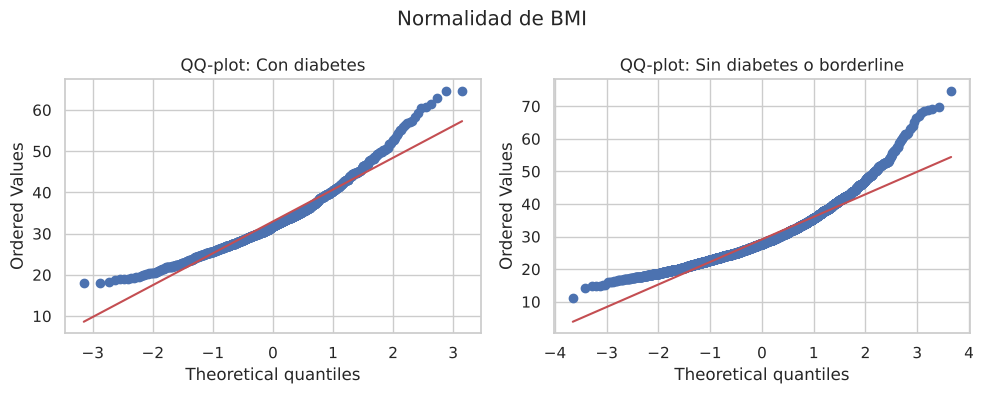

Levene: estadístico = 13.922, p = 0.000192

Test t de Welch: t = 13.211, p = 2.46e-37
Decisión: se rechaza H0
Diferencia de medias = 3.81
Verificación Mann-Whitney U: p = 2.64e-47


In [ ]:
datos_h2 = casos_completos(df_adultos, ["bmi", "diabetes_diagnosed"])

# Grupo 1: diabetes diagnosticada (2). Grupo 2: sin diabetes (0) o borderline (1)
bmi_diabetes = datos_h2.loc[datos_h2["diabetes_diagnosed"] == 2, "bmi"]
bmi_sin_diabetes = datos_h2.loc[datos_h2["diabetes_diagnosed"].isin([0, 1]), "bmi"]
print(f"Con diabetes: {len(bmi_diabetes)} | Sin diabetes o borderline: {len(bmi_sin_diabetes)}")

comparar_medias(bmi_diabetes, bmi_sin_diabetes, "Con diabetes", "Sin diabetes o borderline", "BMI")

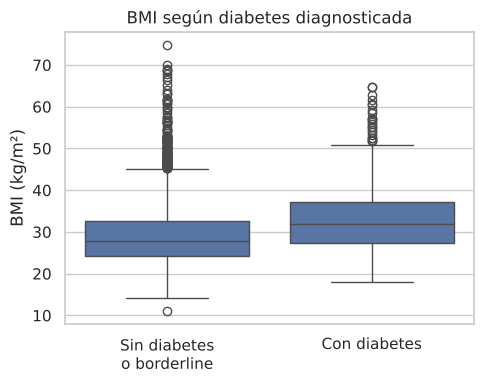

In [ ]:
plt.figure(figsize=(5, 4))
sns.boxplot(x=np.where(datos_h2["diabetes_diagnosed"] == 2, "Con diabetes", "Sin diabetes\no borderline"), y=datos_h2["bmi"])
plt.ylabel("BMI (kg/m²)")
plt.title("BMI según diabetes diagnosticada")
plt.tight_layout()
plt.show()

## 3.3 Hipótesis 3 (multivariada): los parámetros bioquímicos sanguíneos se asocian con la función renal


In [ ]:
PREDICTORAS_H3 = ["blood_urea_nitrogen", "uric_acid", "albumin_serum", "phosphorus", "bicarbonate", "calcium"]

datos_h3 = casos_completos(df_adultos, ["egfr"] + PREDICTORAS_H3)
X_h3 = sm.add_constant(datos_h3[PREDICTORAS_H3])
y_h3 = datos_h3["egfr"]

# Regresión lineal múltiple. El F global contrasta H0: todos los coeficientes = 0
modelo_h3 = sm.OLS(y_h3, X_h3).fit()
print(modelo_h3.summary())   # el summary incluye la prueba de Jarque-Bera de la normalidad de los residuos

Casos completos: 5637 de 8153 filas (2516 descartadas por tener nulos).
                            OLS Regression Results                            
Dep. Variable:                   egfr   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     608.9
Date:                Sun, 08 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:36:41   Log-Likelihood:                -23974.
No. Observations:                5637   AIC:                         4.796e+04
Df Residuals:                    5630   BIC:                         4.801e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------

In [ ]:
# Supuestos de la regresión lineal
# a) Multicolinealidad: VIF (mayor a 5-10 indica problema). Se omite la constante (columna 0).
vif_h3 = pd.Series([variance_inflation_factor(X_h3.values, i) for i in range(1, X_h3.shape[1])],
                   index=PREDICTORAS_H3, name="VIF")
print("VIF:\n", vif_h3.round(2), "\n")

# b) Homocedasticidad: Breusch-Pagan (H0: varianza de los errores constante)
_, bp_p_valor, _, _ = het_breuschpagan(modelo_h3.resid, modelo_h3.model.exog)
print(f"Breusch-Pagan: p = {bp_p_valor:.3g}")

# c) Independencia de los errores: Durbin-Watson (cercano a 2 = sin autocorrelación)
print(f"Durbin-Watson: {durbin_watson(modelo_h3.resid):.2f}")


VIF:
 blood_urea_nitrogen    1.08
uric_acid              1.08
albumin_serum          1.32
phosphorus             1.04
bicarbonate            1.03
calcium                1.37
Name: VIF, dtype: float64 

Breusch-Pagan: p = 1.09e-25
Durbin-Watson: 2.00


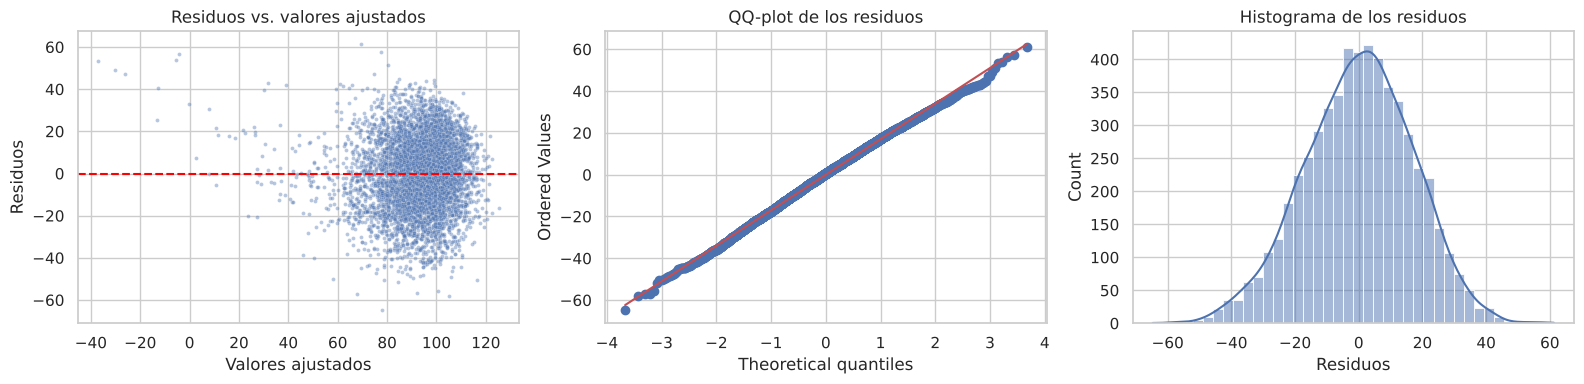

In [ ]:
# d) Distribución de los residuos (normalidad) y homocedasticidad
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(x=modelo_h3.fittedvalues, y=modelo_h3.resid, s=8, alpha=0.4, ax=ejes[0])
ejes[0].axhline(0, color="red", linestyle="--")
ejes[0].set(xlabel="Valores ajustados", ylabel="Residuos", title="Residuos vs. valores ajustados")
stats.probplot(modelo_h3.resid, dist="norm", plot=ejes[1])
ejes[1].set_title("QQ-plot de los residuos")
sns.histplot(modelo_h3.resid, bins=40, kde=True, ax=ejes[2])
ejes[2].set(xlabel="Residuos", title="Histograma de los residuos")
plt.tight_layout()
plt.show()

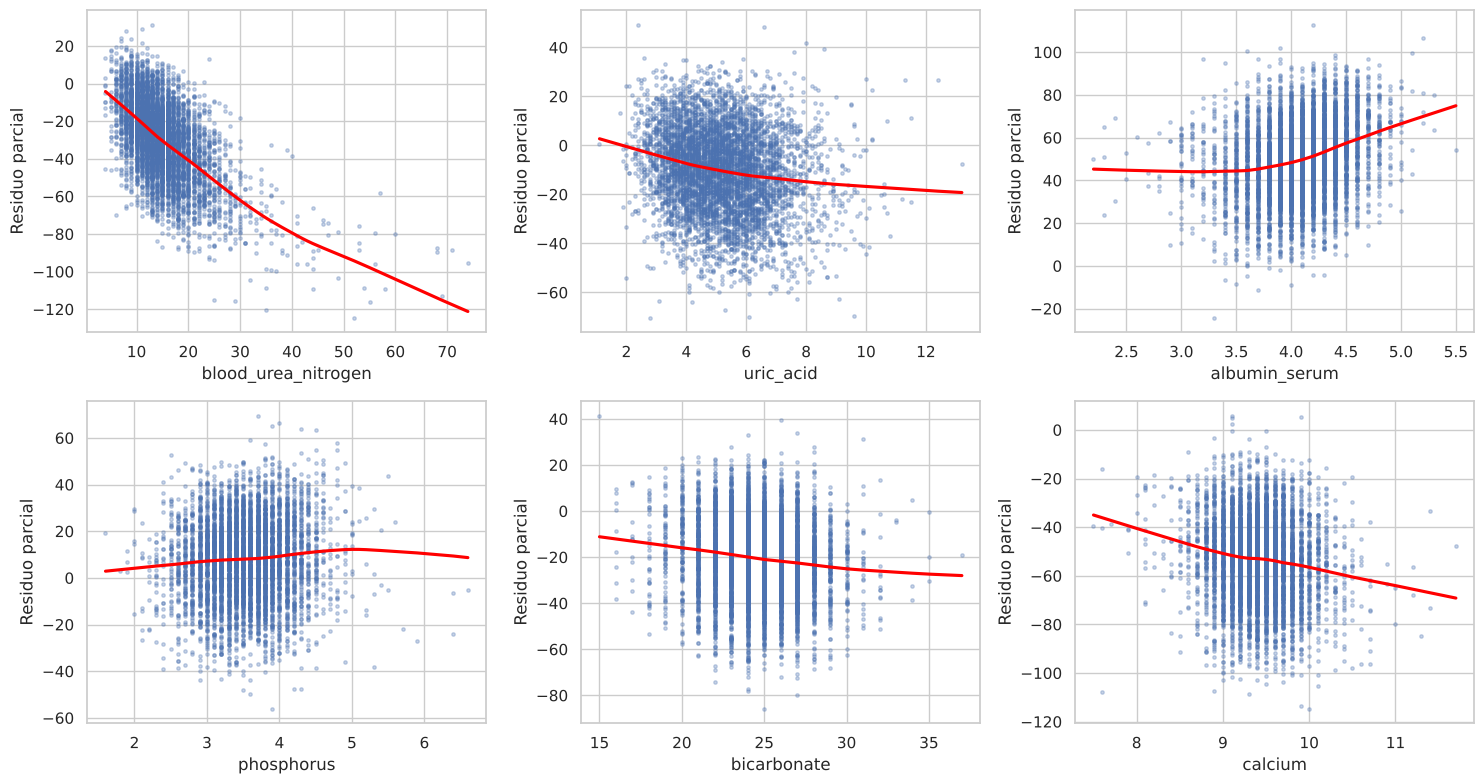

In [ ]:
# e) Linealidad de cada predictor: residuo parcial vs. predictor (la línea roja lowess debería ser aproximadamente recta)
fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, variable in zip(ejes.ravel(), PREDICTORAS_H3):
    residuo_parcial = modelo_h3.resid + modelo_h3.params[variable] * datos_h3[variable]
    sns.regplot(x=datos_h3[variable], y=residuo_parcial, lowess=True,
                scatter_kws={"s": 6, "alpha": 0.3}, line_kws={"color": "red"}, ax=eje)
    eje.set(xlabel=variable, ylabel="Residuo parcial")
plt.tight_layout()
plt.show()

## 3.4 Hipótesis 4: la mayoría de los casos de CKD corresponde a blancos no hispánicos


In [ ]:
# Casos de CKD (ckd_present = 1) con etnia disponible; los de estado desconocido ya son NaN y quedan afuera
casos_ckd = df_adultos[df_adultos["ckd_present"] == 1].dropna(subset=["ethnicity"])
n_casos = len(casos_ckd)
n_blancos = (casos_ckd["ethnicity"] == "Non-Hispanic White").sum()
print(f"Casos de CKD: {n_casos} | blancos no hispanos: {n_blancos} | proporción observada = {n_blancos / n_casos:.4f}")

# Test z de una proporción, unilateral (error estándar bajo H0)
z, p_valor = proportions_ztest(count=n_blancos, nobs=n_casos, value=0.5, alternative="larger", prop_var=0.5)
print(f"Test z: z = {z:.3f}, p = {p_valor:.3g}")
print("Decisión:", "se rechaza H0" if p_valor <= ALFA else "no se rechaza H0")


Casos de CKD: 2647 | blancos no hispanos: 1708 | proporción observada = 0.6453
Test z: z = 14.947, p = 8.17e-51
Decisión: se rechaza H0


In [ ]:
# Contexto (la limitación de la hipótesis): composición de los casos vs. de la muestra analizada, y prevalencia por grupo
con_ckd_conocido = df_adultos[df_adultos["ckd_present"].notna()]
pd.DataFrame({
    "% de los casos de CKD": casos_ckd["ethnicity"].value_counts(normalize=True) * 100,
    "% de la muestra analizada": con_ckd_conocido["ethnicity"].value_counts(normalize=True) * 100,
    "prevalencia de CKD (%)": con_ckd_conocido.groupby("ethnicity")["ckd_present"].mean() * 100,
}).sort_values("% de los casos de CKD", ascending=False).round(1)

,% de los casos de CKD,% de la muestra analizada,prevalencia de CKD (%)
ethnicity,,,
Non-Hispanic White,64.5,59.2,51.0
Non-Hispanic Black,13.9,11.6,55.9
Other Hispanic,8.2,10.4,36.8
Other/Multiracial,6.1,6.3,45.6
Mexican American,3.9,7.1,25.8
Non-Hispanic Asian,3.4,5.5,29.4


## 3.5 Hipótesis 5: la presión arterial es un factor asociado a la presencia de CKD


Casos completos: 5484 de 8153 filas (2669 descartadas por tener nulos).
Con CKD: 2578 | Sin CKD: 2906


,count,mean,std,50%
Con CKD,2578.0,127.28,20.00,125.0
Sin CKD,2906.0,117.93,15.18,116.0


Shapiro-Wilk (Con CKD): W = 0.9634, p = 4.68e-25
Shapiro-Wilk (Sin CKD): W = 0.9756, p = 6.88e-22


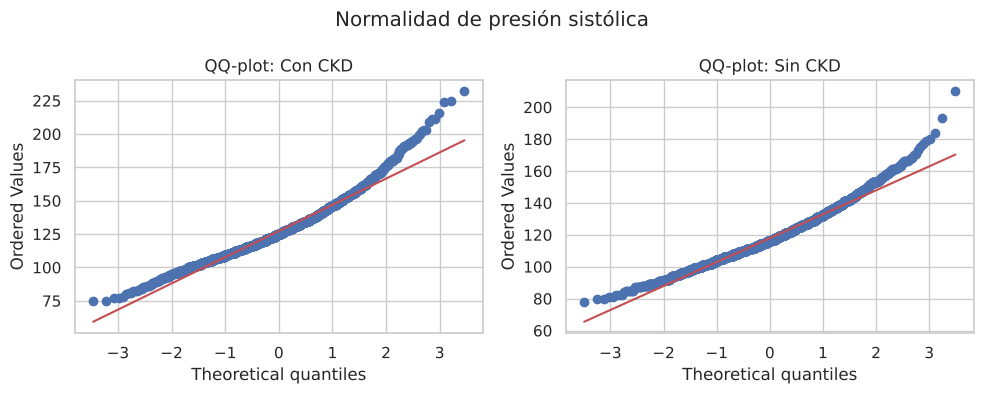

Levene: estadístico = 126.306, p = 5.46e-29

Test t de Welch: t = 19.323, p = 1.85e-80
Decisión: se rechaza H0
Diferencia de medias = 9.36
Verificación Mann-Whitney U: p = 4.43e-76


In [ ]:
datos_h5 = casos_completos(df_adultos, ["ckd_present", "bp_systolic"])
bp_ckd = datos_h5.loc[datos_h5["ckd_present"] == 1, "bp_systolic"]
bp_sin_ckd = datos_h5.loc[datos_h5["ckd_present"] == 0, "bp_systolic"]
print(f"Con CKD: {len(bp_ckd)} | Sin CKD: {len(bp_sin_ckd)}")

comparar_medias(bp_ckd, bp_sin_ckd, "Con CKD", "Sin CKD", "presión sistólica")

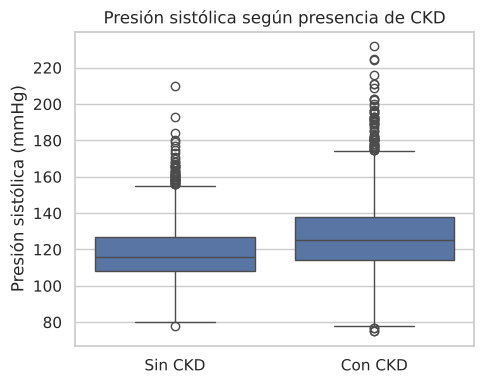

In [ ]:
plt.figure(figsize=(5, 4))
sns.boxplot(x=np.where(datos_h5["ckd_present"] == 1, "Con CKD", "Sin CKD"), y=datos_h5["bp_systolic"])
plt.ylabel("Presión sistólica (mmHg)")
plt.title("Presión sistólica según presencia de CKD")
plt.tight_layout()
plt.show()

## 3.6 Hipótesis 6: existe un vínculo entre edad, sexo, BMI, presión arterial, diabetes, tabaquismo y nivel socioeconómico y la probabilidad de presentar CKD


In [ ]:
PREDICTORAS_H6 = ["age", "gender", "bmi", "bp_systolic", "diabetes_diagnosed", "ever_smoked", "poverty_income_ratio"]


def ajustar_logit(df, columna_ckd):
    """
    Regresión logística de `columna_ckd` sobre PREDICTORAS_H6 con los casos completos.
    Las categóricas se pasan a etiquetas y luego a indicadores (0/1) descartando la categoría de referencia
    (mujer, sin diabetes, nunca fumó), para que los coeficientes sean legibles y no se traten como numéricos.
    Devuelve el modelo, la matriz de predictoras, la variable resultado y la tabla de odds ratios.
    """
    datos = casos_completos(df, [columna_ckd] + PREDICTORAS_H6).copy()
    datos["diabetes"] = datos["diabetes_diagnosed"].map({0: "No", 1: "Borderline", 2: "Sí"})
    datos["fumo_alguna_vez"] = datos["ever_smoked"].map({0: "No", 1: "Sí"})

    y = datos[columna_ckd].astype(int)
    X = pd.get_dummies(datos[["age", "gender", "bmi", "bp_systolic", "poverty_income_ratio", "diabetes", "fumo_alguna_vez"]],
                       columns=["gender", "diabetes", "fumo_alguna_vez"], dtype=float)
    X = X.drop(columns=["gender_Female", "diabetes_No", "fumo_alguna_vez_No"])   # categorías de referencia
    X = sm.add_constant(X)

    modelo = sm.Logit(y, X).fit(disp=0)
    intervalos = np.exp(modelo.conf_int())
    tabla_or = pd.DataFrame({"OR": np.exp(modelo.params), "IC95_inf": intervalos[0],
                             "IC95_sup": intervalos[1], "p_valor": modelo.pvalues}).drop(index="const")
    return modelo, X, y, tabla_or


modelo_h6, X_h6, y_h6, tabla_or_h6 = ajustar_logit(df_adultos, "ckd_present")
print(f"Sin CKD: {(y_h6 == 0).sum()} | Con CKD: {(y_h6 == 1).sum()}\n")
print(modelo_h6.summary())

Casos completos: 4738 de 8153 filas (3415 descartadas por tener nulos).
Sin CKD: 2518 | Con CKD: 2220

                           Logit Regression Results                           
Dep. Variable:            ckd_present   No. Observations:                 4738
Model:                          Logit   Df Residuals:                     4729
Method:                           MLE   Df Model:                            8
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                  0.2261
Time:                        01:36:42   Log-Likelihood:                -2534.5
converged:                       True   LL-Null:                       -3274.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -5.4104      0.305    -17.733      0.000      -6.008      -4.81

In [ ]:
# Prueba global de razón de verosimilitudes contra el modelo nulo (solo intercepto)
print(f"Razón de verosimilitudes: estadístico = {modelo_h6.llr:.1f}, gl = {int(modelo_h6.df_model)}, p = {modelo_h6.llr_pvalue:.3g}  (0 = menor que la precisión numérica)")
print(f"Pseudo R² de McFadden: {modelo_h6.prsquared:.3f}")
print(f"AUC (capacidad de discriminación): {roc_auc_score(y_h6, modelo_h6.predict(X_h6)):.3f}")

# Multicolinealidad (se omite la constante)
vif_h6 = pd.Series([variance_inflation_factor(X_h6.values, i) for i in range(1, X_h6.shape[1])],
                   index=X_h6.columns[1:], name="VIF")
print("\nVIF máximo:", round(vif_h6.max(), 2))

# Odds ratios con IC 95% y p-valor de cada variable
tabla_or_h6.round(4)

Razón de verosimilitudes: estadístico = 1480.6, gl = 8, p = 0  (0 = menor que la precisión numérica)
Pseudo R² de McFadden: 0.226
AUC (capacidad de discriminación): 0.807

VIF máximo: 1.29


,OR,IC95_inf,IC95_sup,p_valor
age,1.0742,1.0689,1.0795,0.0000
bmi,1.0142,1.0043,1.0241,0.0046
bp_systolic,1.0088,1.0047,1.0129,0.0000
poverty_income_ratio,0.9757,0.9354,1.0177,0.2519
gender_Male,0.9833,0.8563,1.1292,0.8117
diabetes_Borderline,0.7615,0.5342,1.0854,0.1319
diabetes_Sí,1.0943,0.8951,1.3378,0.3795
fumo_alguna_vez_Sí,1.0095,0.8775,1.1614,0.8947
